In [2]:


import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
import behavior
# from activitymode import Mode

cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 

In [252]:
path = r'G:\ephys_data\CW65\python\2025_02_25'
# path = r'K:\data\CW69\python\2025_12_19'
path=r'H:\ephys_data\CW47\python\2024_10_25'

# path = r'M:\data\CW75\python\2026_03_04'
# path = r'K:\data\CW84\python\2026_03_11'
# path = r'M:\data\CW80\python\2026_04_05'
path = r'L:\data\CW68\python\2025_12_15'
# path = r'K:\data\CW85\python\2026_02_13'
# path = r'M:\data\CW87\python\2026_02_22'
# path = r'J:\ephys_data\CW53\python\2025_01_27'
path = r'P:\data\CW92\python\2026_07_01'
# path = r'P:\data\CW95\python\2026_06_01'
s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
_, _, proportion_correct = s1.performance_in_trials(s1.i_good_trials)
# print(np.mean(correctarr))
print(proportion_correct)

Remove 0 trials from session for bad behavior
2 trials removed for stability reasons
only ppyr neurons: 194 --> 147
0.7255434782608695


In [249]:
len(s1.i_good_trials), good_trial_inds.shape, earlylick.shape


(368, (414,), (429,))

In [253]:
s1.i_good_R_stim_trials, s1.i_good_trials

([25,
  33,
  46,
  49,
  50,
  52,
  53,
  56,
  59,
  82,
  86,
  88,
  89,
  92,
  95,
  99,
  103,
  106,
  108,
  113,
  124,
  128,
  129,
  137,
  138,
  141,
  145,
  148,
  152,
  155,
  164,
  172,
  173,
  175,
  181,
  192,
  195,
  196,
  239,
  240,
  247,
  248,
  260,
  263,
  266,
  267,
  271,
  273,
  274,
  278,
  279,
  281,
  284,
  288,
  290,
  292,
  293,
  299,
  307,
  308,
  318,
  321,
  322,
  345,
  347,
  348,
  354,
  356,
  360,
  368,
  370,
  383,
  384,
  386,
  390],
 array([ 24,  25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,
         37,  38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,
         50,  51,  52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,
         63,  64,  65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,
         76,  77,  78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,
         89,  90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101,
        102, 103, 104, 105, 106, 107, 108, 109, 110,

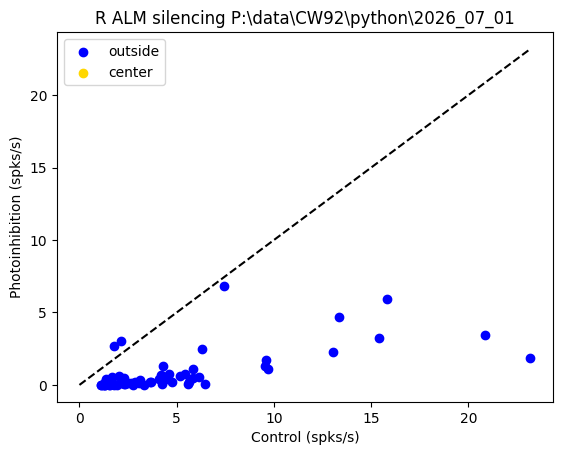

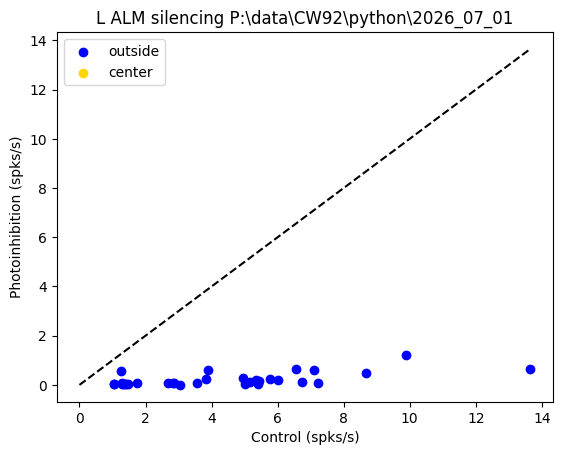

In [254]:
stim_spk, ctl_spk = [],[]
center_idx = []

sided_neurons = s1.good_neurons # s1.L_alm_idx
sided_neurons = s1.R_alm_idx
# stim_trials = s1.i_good_bi_stim_trials # s1.i_good_L_stim_trials
stim_trials = s1.i_good_R_stim_trials

window = (0.570 + 1.3 + 0, 0.570 + 1.3 + 1.0) # First second of delay
# window = (0.570 + 1.3 + 0, 0.570 + 1.3 + 0.8) # First 0.8s of delay
counter = 0
for n in sided_neurons:
    # if s1.shank[n] == 1 or s1.shank[n] == 4:
    #     center_idx += [n]
    #     continue 
    ctl_rate = s1.get_spike_rate(n, window, s1.i_good_non_stim_trials)
    if ctl_rate < 1:
        continue
    stim_spk += [s1.get_spike_rate(n, window, stim_trials)]
    ctl_spk += [ctl_rate]
    
    if not hasattr(s1, 'shank'):
        # print("Warning: 's1.shank' attribute does not exist. Skipping center_idx classification.")
        center_idx += [counter]
        continue
    if s1.shank[n] == 2 or s1.shank[n] == 3:
        center_idx += [counter]
        
    counter += 1
    
    
f = plt.figure()
plt.scatter(ctl_spk, stim_spk, color='blue', label ='outside')
plt.scatter(np.array(ctl_spk)[center_idx], np.array(stim_spk)[center_idx], color='gold', label='center')
plt.plot([0, max(ctl_spk)], [0, max(ctl_spk)], ls='--', color='black')
plt.ylabel('Photoinhibition (spks/s)')
plt.xlabel('Control (spks/s)')
plt.title('R ALM silencing {}'.format(path))
plt.legend()
plt.show()



sided_neurons = s1.L_alm_idx
# stim_trials = s1.i_good_bi_stim_trials # s1.i_good_L_stim_trials
stim_trials = s1.i_good_L_stim_trials
stim_spk, ctl_spk = [],[]

counter = 0
for n in sided_neurons:
    # if s1.shank[n] == 1 or s1.shank[n] == 4:
    #     center_idx += [n]
    #     continue 
    ctl_rate = s1.get_spike_rate(n, window, s1.i_good_non_stim_trials)
    if ctl_rate < 1:
        continue
    stim_spk += [s1.get_spike_rate(n, window, stim_trials)]
    ctl_spk += [ctl_rate]
    if not hasattr(s1, 'shank'):
        # print("Warning: 's1.shank' attribute does not exist. Skipping center_idx classification.")
        center_idx += [counter]
        continue
    if s1.shank[n] == 2 or s1.shank[n] == 3:
        center_idx += [counter]
        
    counter += 1
    
    
f = plt.figure()
plt.scatter(ctl_spk, stim_spk, color='blue', label ='outside')
plt.scatter(np.array(ctl_spk)[center_idx], np.array(stim_spk)[center_idx], color='gold', label='center')
plt.plot([0, max(ctl_spk)], [0, max(ctl_spk)], ls='--', color='black')
plt.ylabel('Photoinhibition (spks/s)')
plt.xlabel('Control (spks/s)')
plt.title('L ALM silencing {}'.format(path))
plt.legend()
plt.show()


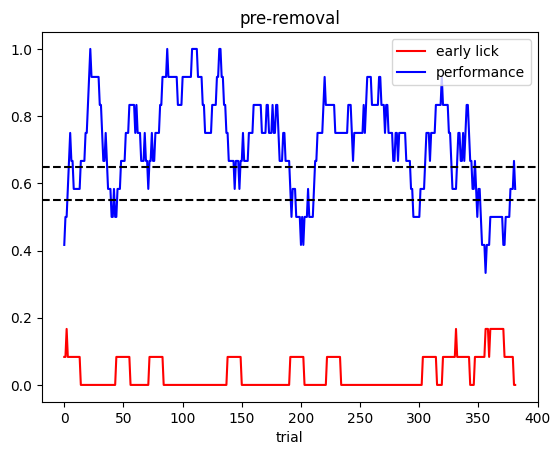

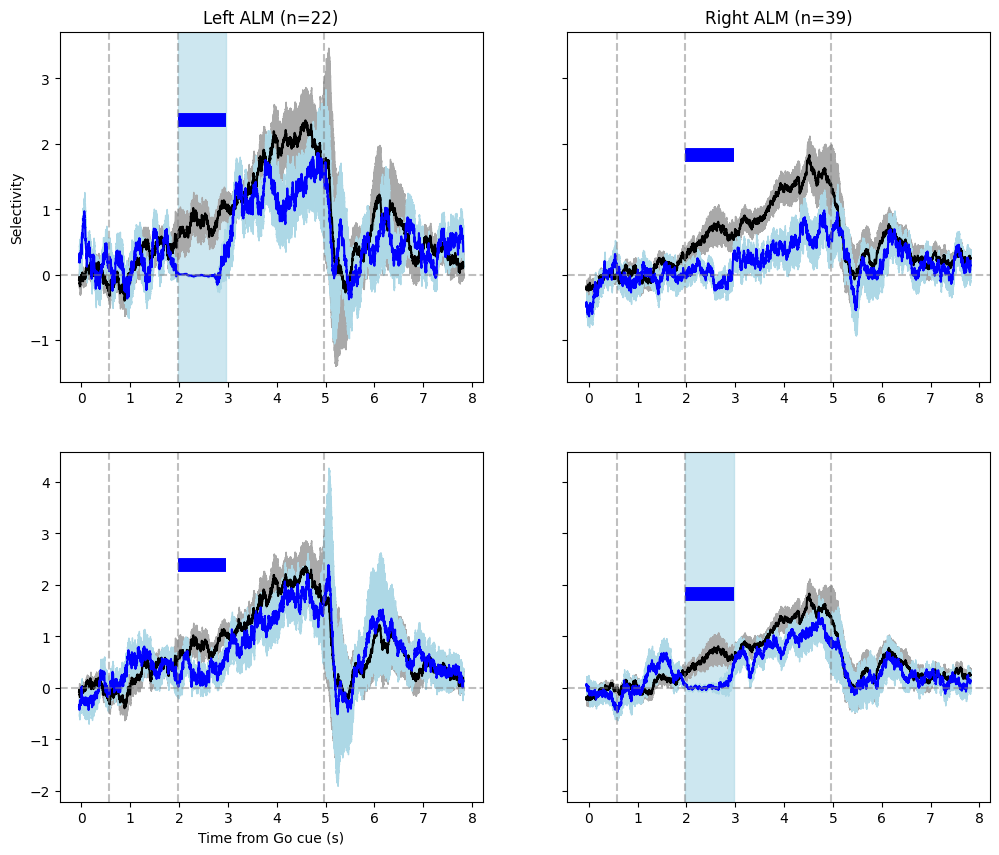

In [255]:
earlylick, correctarr, numtrials = s1.get_acc_conv(window=12,use_all_trials=True)

plt.plot(earlylick, 'r' ,label='early lick')

plt.plot(correctarr, 'b', label='performance')
# Overlay both earlylick and correctarr in green if belonging to s1.i_good_trials

# For each trial in i_good_trials, plot the corresponding points in green
good_trial_inds = s1.i_good_trials

# Plot earlylick values in green at good trial indices
# plt.plot(good_trial_inds, np.array(earlylick)[good_trial_inds], 'g', label='early lick (good trials)')

# Plot correctarr values in green at good trial indices
# plt.plot(good_trial_inds, np.array(correctarr)[good_trial_inds], 'g', label='performance (good trials)')

plt.axhline(0.55, color='k', linestyle='--')
plt.axhline(0.65, color='k', linestyle='--')
plt.xlabel('trial')
plt.title('pre-removal')
plt.legend()

# s1.delay, s1.response = 1.77, 3.47
# s1.delay, s1.response = 1.77, 3.47
epoch = (s1.delay, s1.response)
# epoch = (s1.sample, s1.delay)
# epoch = (1.77, 3.47)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.05, 
                                                    binsize=150, 
                                                    timestep=50,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)

Text(0.5, 1.0, 'post-removal')

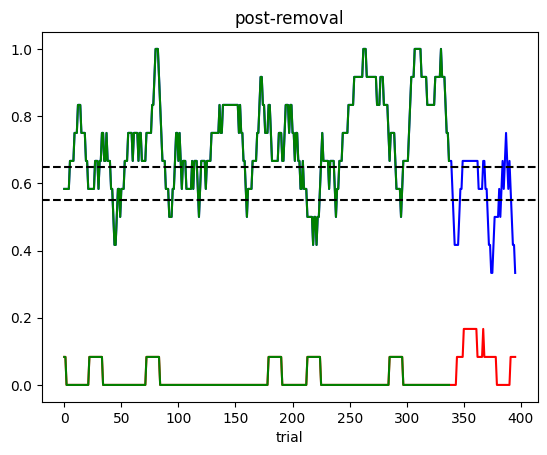

In [209]:
earlylick, correctarr, numtrials = s1.get_acc_conv(window=12, use_all_trials=True)

plt.plot(earlylick, 'r' ,label='early lick')

plt.plot(correctarr, 'b', label='performance')
# Overlay both earlylick and correctarr in green if belonging to s1.i_good_trials

# For each trial in i_good_trials, plot the corresponding points in green
good_trial_inds = np.concatenate([
                                range(0,338),
                                # range(380, 428),
                                # range(0, 458),
                                # range(240, 255),
                                # range(252, 370),
                                # range(252, 310),
                                # range(325, 340),
                                    ])
# good_trial_inds = np.load(s1.path + r'\good_trial_inds.npy')



# Plot earlylick values in green at good trial indices
plt.plot(good_trial_inds, np.array(earlylick)[good_trial_inds], 'g', label='early lick (good trials)')

# Plot correctarr values in green at good trial indices
plt.plot(good_trial_inds, np.array(correctarr)[good_trial_inds], 'g', label='performance (good trials)')

plt.axhline(0.55, color='k', linestyle='--')
plt.axhline(0.65, color='k', linestyle='--')
plt.xlabel('trial')
plt.title('post-removal')
# plt.legend()

In [210]:
# replace by new i_good_trials
_, _, proportion_correct = s1.performance_in_trials(good_trial_inds)
print(proportion_correct), s1.delay, s1.response

0.7248520710059172


(None, 1.9699999999999998, 4.97)

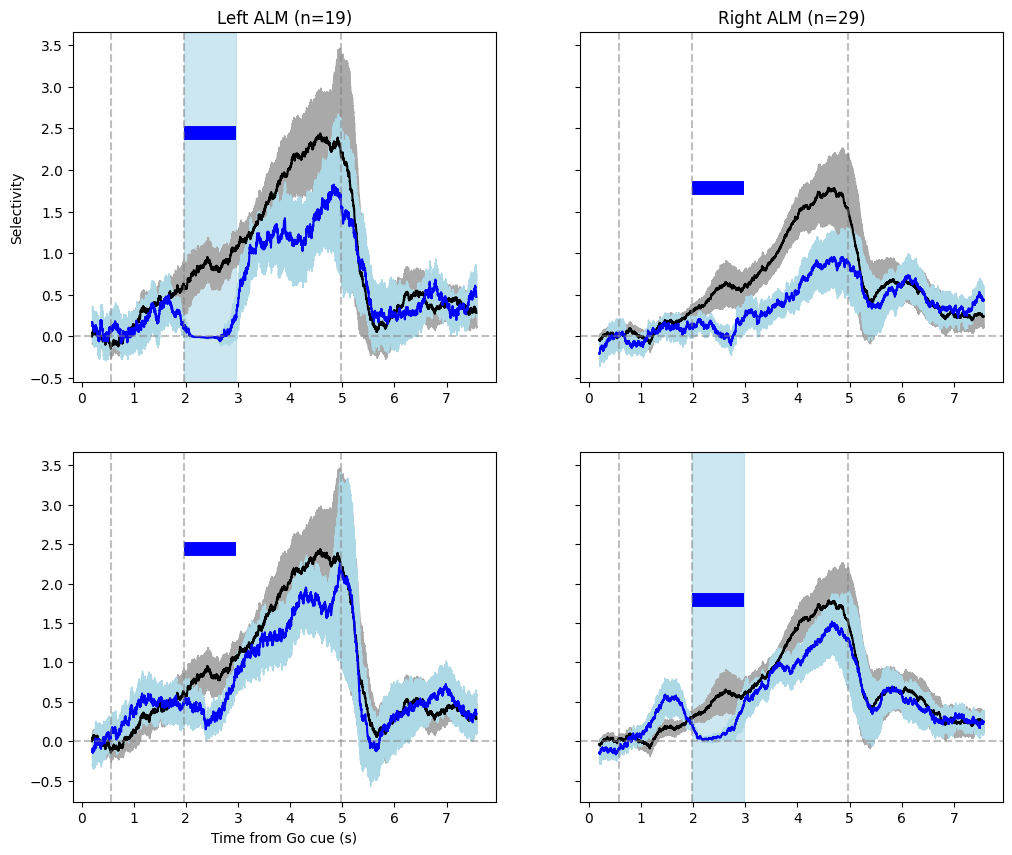

In [256]:
# Plot selectivity recovery to check
s1.i_good_trials = good_trial_inds
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)

# Save i good trials

# np.save(s1.path + r'\good_trial_inds.npy', good_trial_inds)



In [ ]:
# CW69, 12/19 good_trial_inds = np.concatenate([range(50,68), range(79, 95),range(115,145), range(159, 199),range(220,237), range(251,278), range(288, 298), range(315, 325), range(337, 345)])

# CW68, 12/10 good_trial_inds = np.concatenate([range(19,70), range(100,147), range(183,250), range(264, 322), range(365, 450)])
# CW68, 12/13 good_trial_inds = np.concatenate([range(0, 48), range(62,255),range(270,330), range(350,380)])
# CW68, 12/16 good_trial_inds = np.concatenate([range(0, 68), 
                                    # range(83,194), 
                                    # # range(211, 222),
                                    # range(211,265),
                                    # range(295,363)
                                    # # range(233, 265),
                                    # # range(295,322),
                                    # # range(332,363),
                                    # ])
# CW65 2/25 good_trial_inds = np.concatenate([range(45, 143), 
#                                     # range(160, 180), 
#                                     # range(192, 204), 
#                                     # range(229, 246), 
#                                     # range(282, 350), 
#                                     range(160, 250),
#                                     range(280, 350),
#                                     ])

In [7]:
def plot_selectivity_recovery(s1, left_info, right_info):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    # axarr[1,1].set_ylim(bottom=-2)

    plt.show()

## Single neuron examples:

For problem sessions:
- CW65, 2/24
- CW47





In [ ]:
path = r'G:\ephys_data\CW65\python\2025_02_25'

s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
_, _, proportion_correct = s1.performance_in_trials(s1.i_good_trials)
# print(np.mean(correctarr))
print(proportion_correct)

34 trials removed for stability reasons
only ppyr neurons: 407 --> 347
0.5093167701863354


In [58]:
good_trial_inds = np.load(s1.path + r'\good_trial_inds.npy')
s1.i_good_trials = good_trial_inds

In [80]:
# s1.R_alm_idx.pop(10)
s1.R_alm_idx 

[240,
 243,
 244,
 245,
 246,
 247,
 248,
 249,
 250,
 252,
 253,
 254,
 258,
 261,
 262,
 263,
 264,
 265,
 266,
 267,
 268,
 269,
 271,
 273,
 274,
 275,
 276,
 277,
 278,
 279,
 282,
 283,
 284,
 285,
 287,
 288,
 289,
 290,
 293,
 294,
 295,
 296,
 297,
 298,
 299,
 300,
 301,
 303,
 304,
 305,
 306,
 307,
 308,
 309,
 310,
 311,
 312,
 313,
 315,
 316,
 317,
 318,
 319,
 320,
 324,
 327,
 328,
 329,
 330,
 331,
 333,
 335,
 336,
 337,
 338,
 339,
 340,
 341,
 342,
 343,
 344,
 345,
 346,
 347,
 348,
 349,
 350,
 351,
 352,
 353,
 355,
 356,
 358,
 359,
 360,
 361,
 362,
 363,
 364,
 365,
 366,
 368,
 369,
 371,
 372,
 373,
 374,
 375,
 376,
 377,
 378,
 379,
 380,
 381,
 382,
 383,
 384,
 385,
 386,
 387,
 388,
 389,
 390,
 391,
 393,
 394,
 395,
 396,
 397,
 398,
 399,
 400,
 401,
 402,
 403,
 404,
 405,
 406]

65


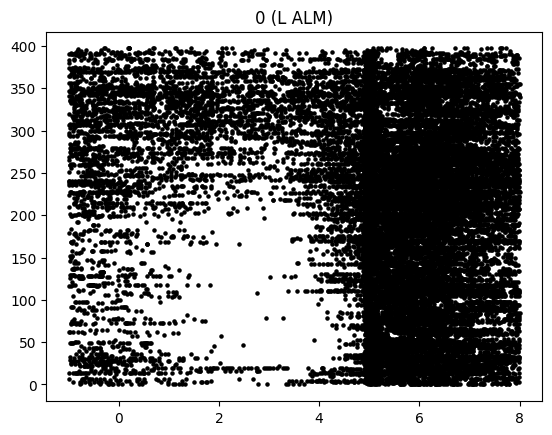

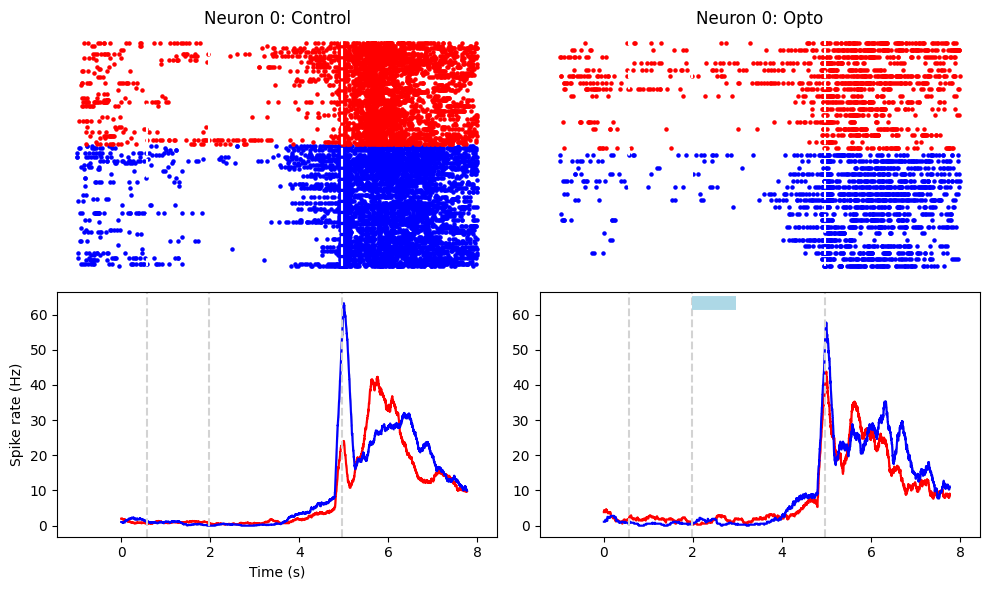

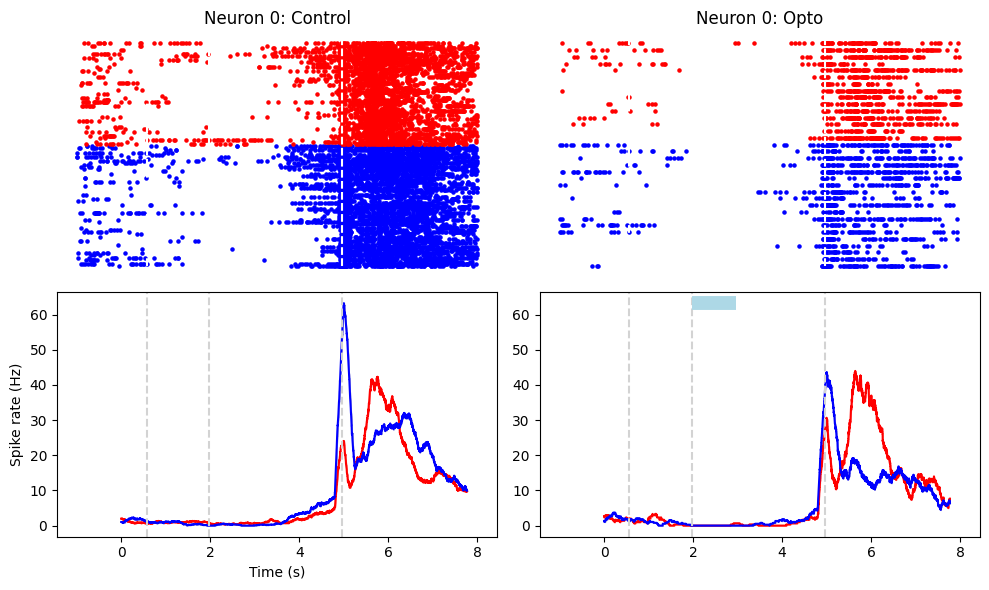

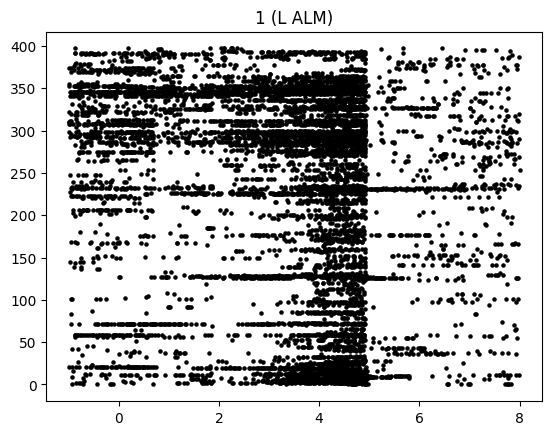

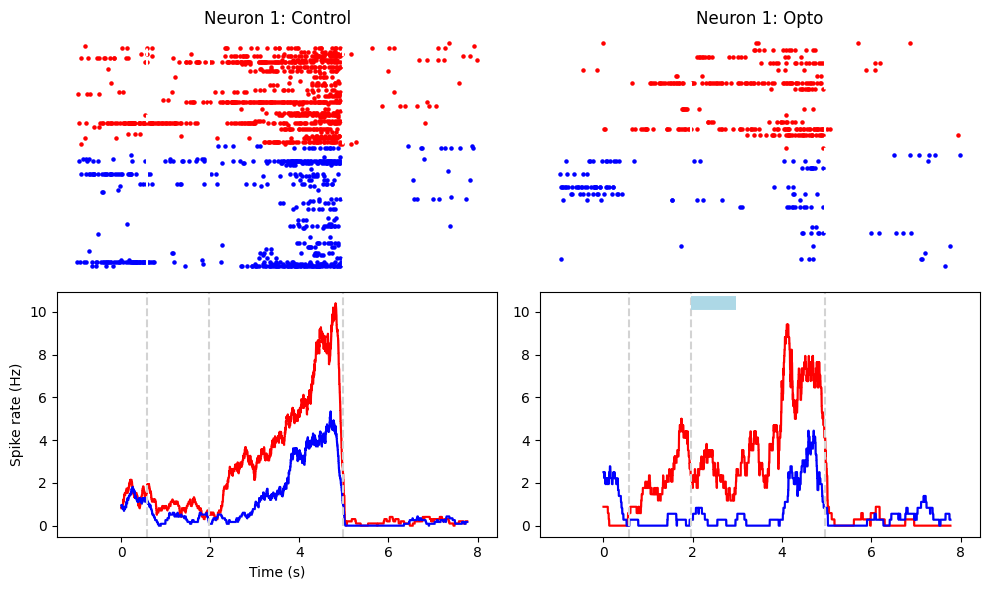

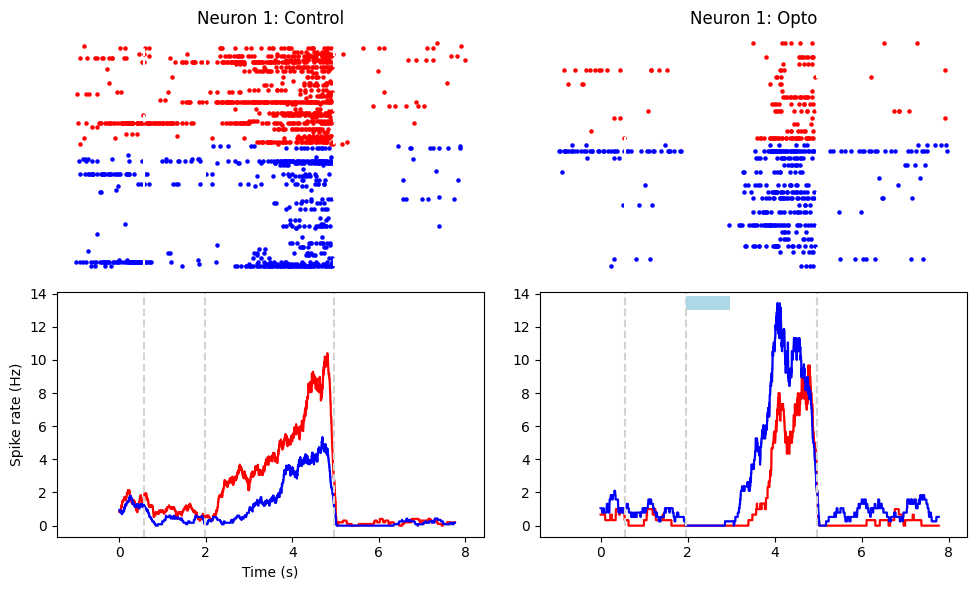

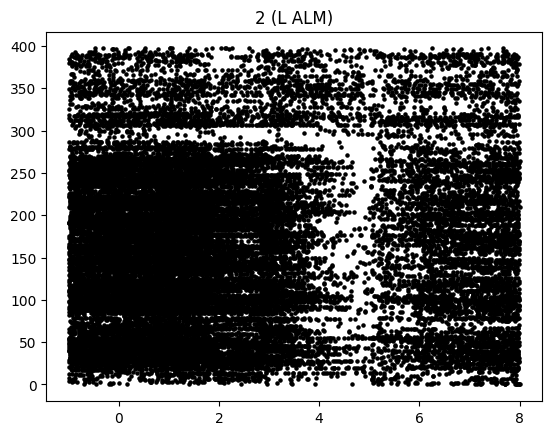

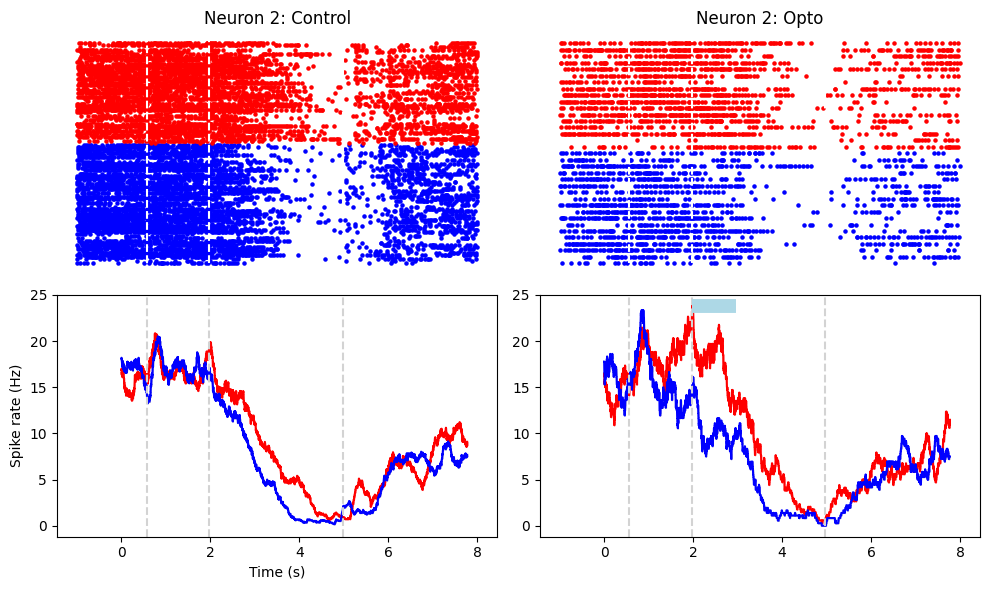

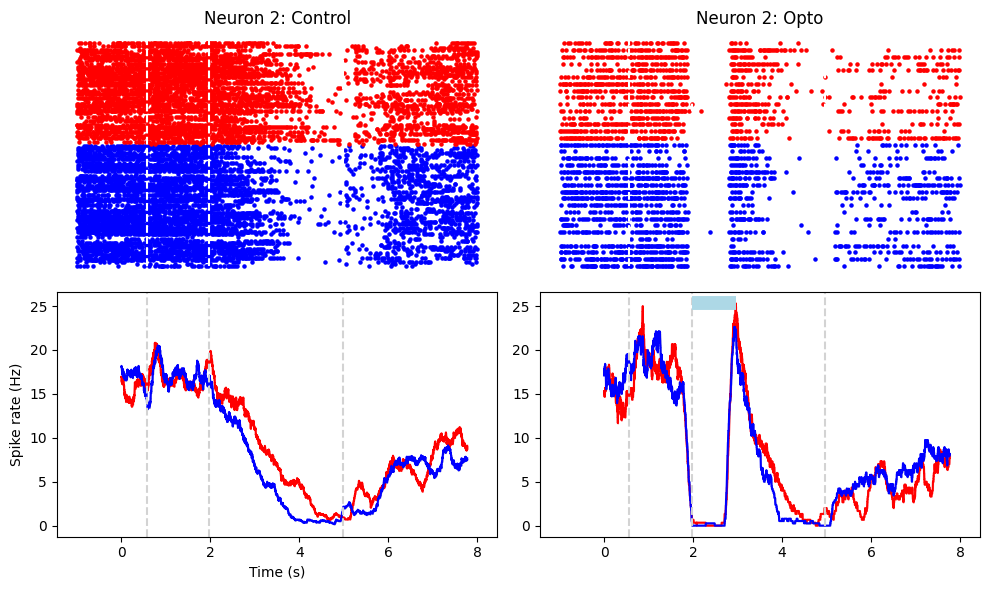

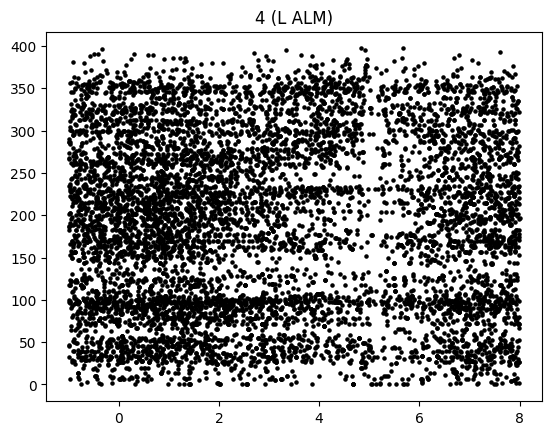

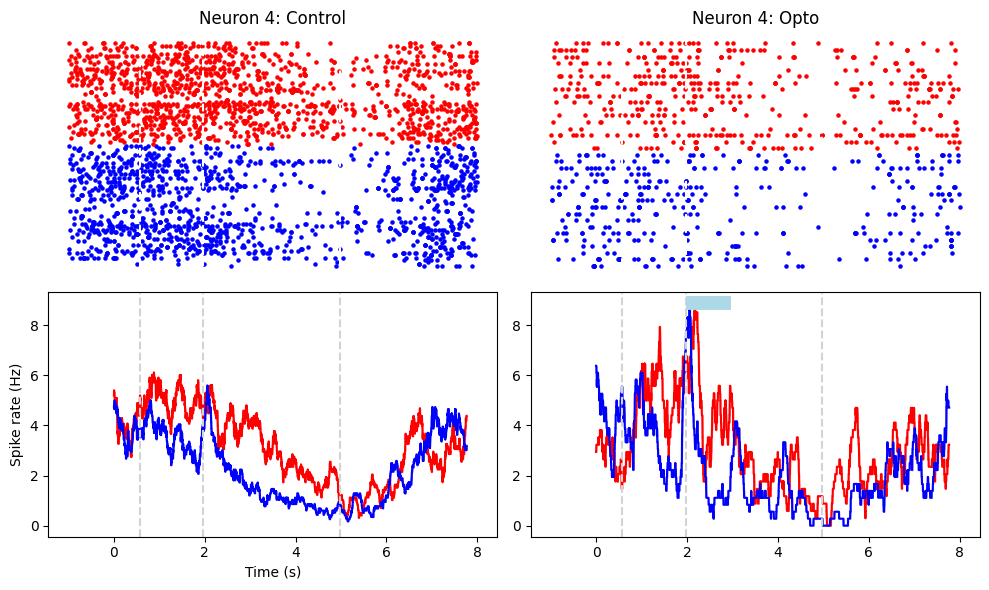

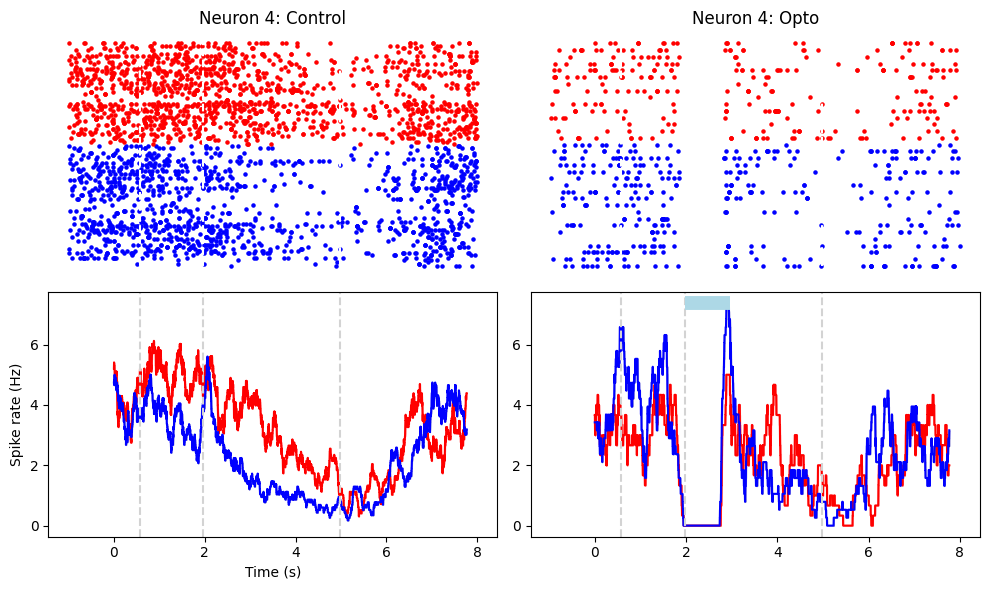

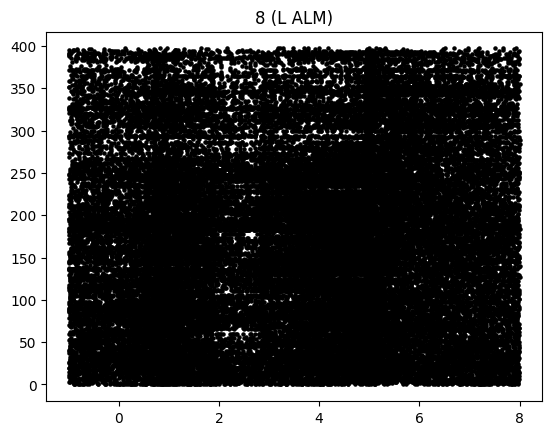

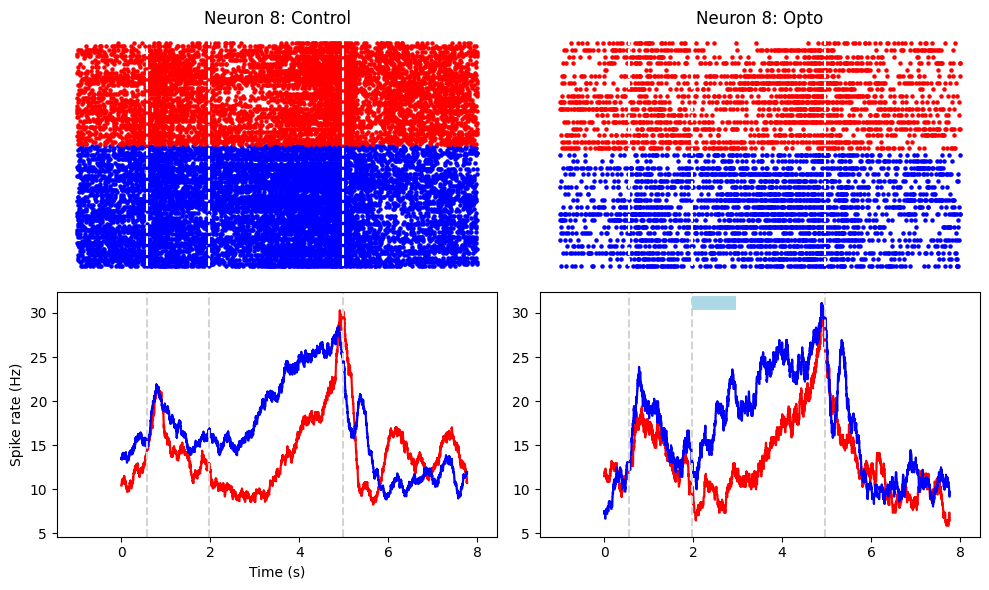

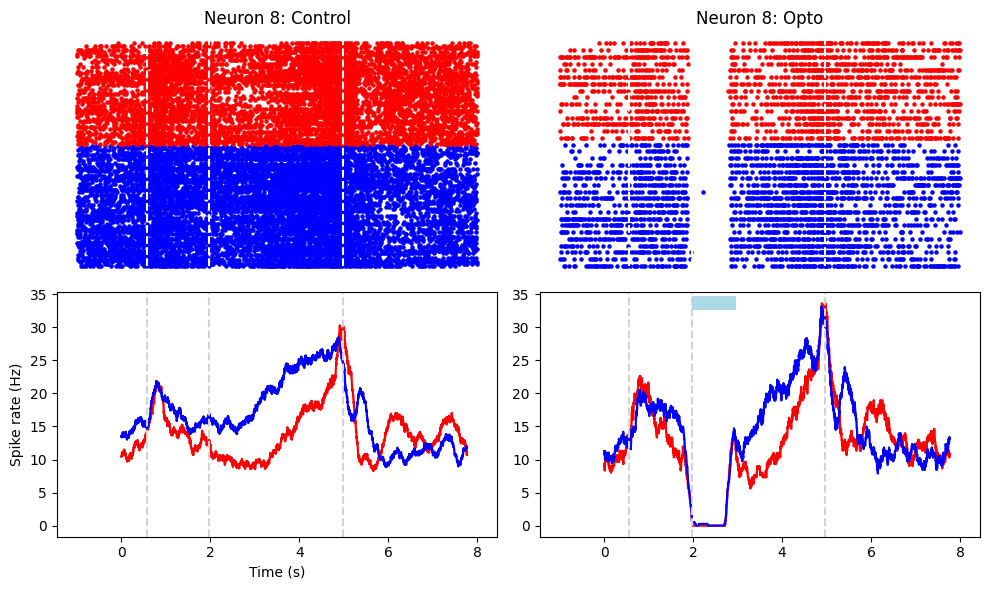

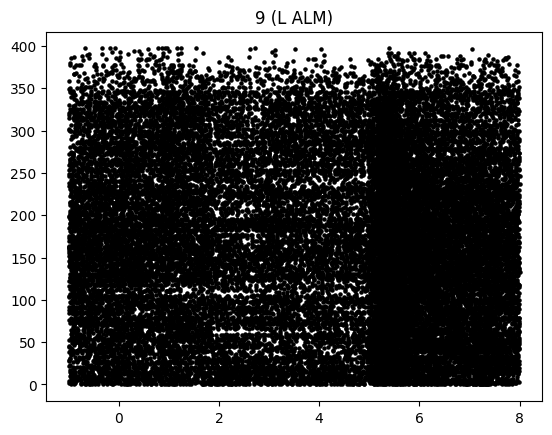

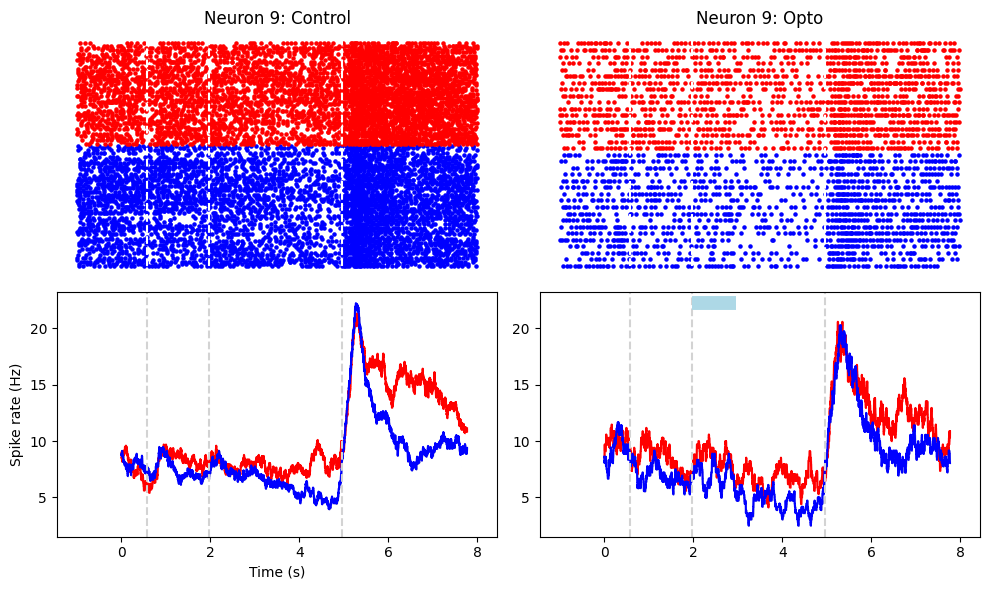

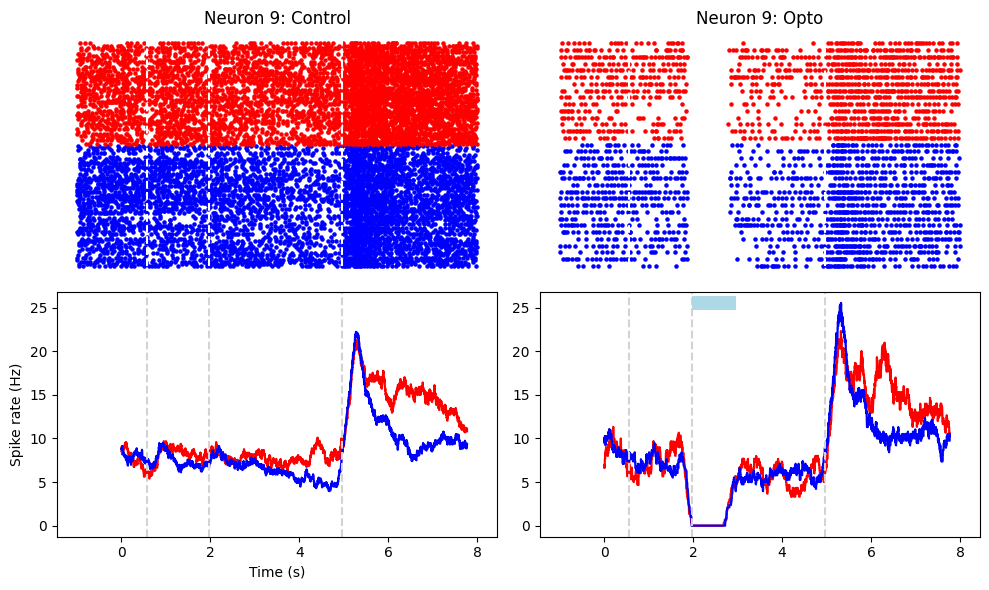

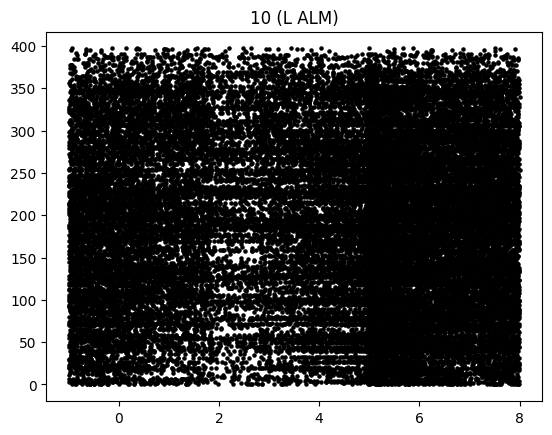

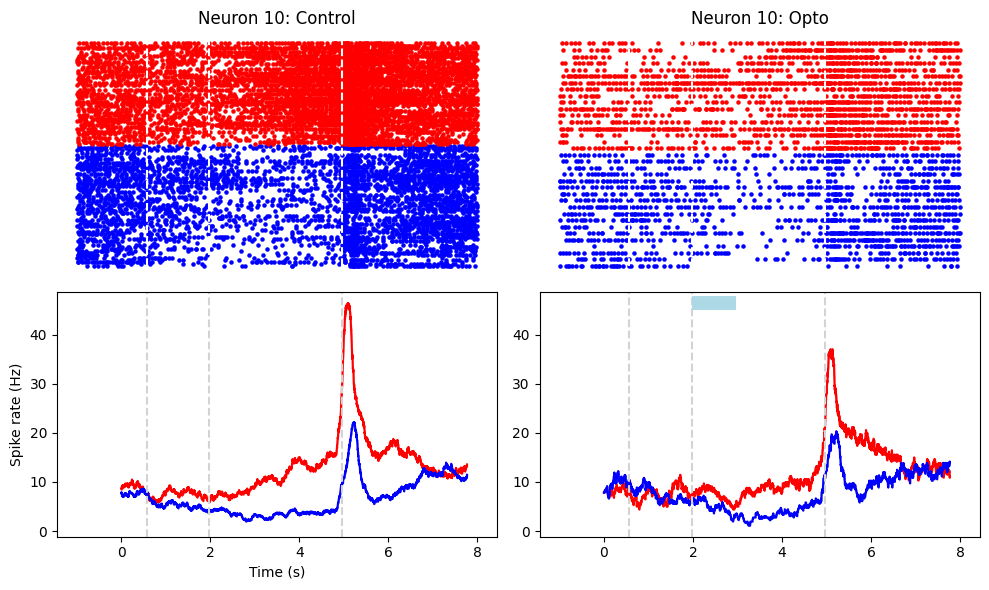

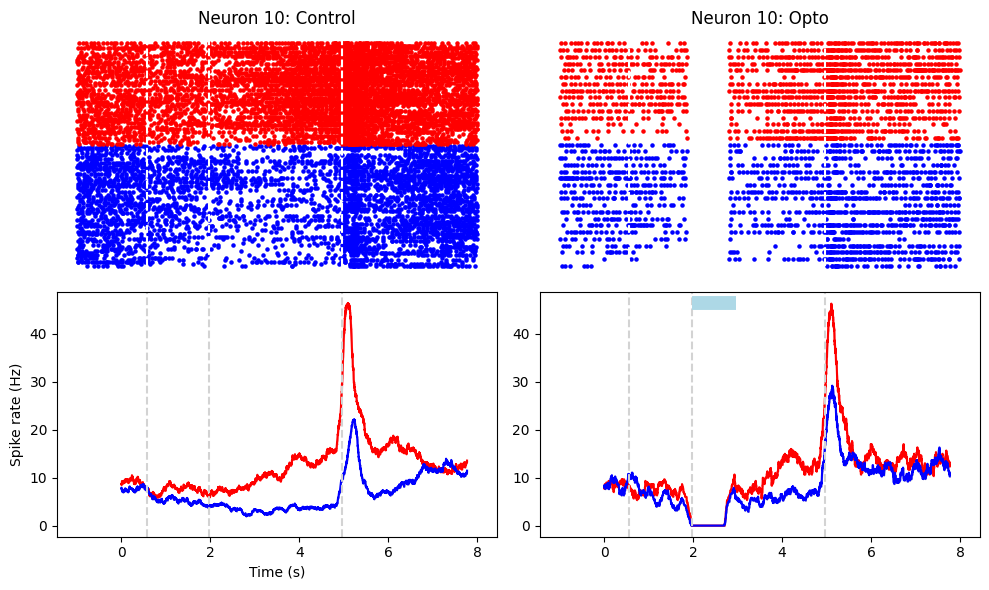

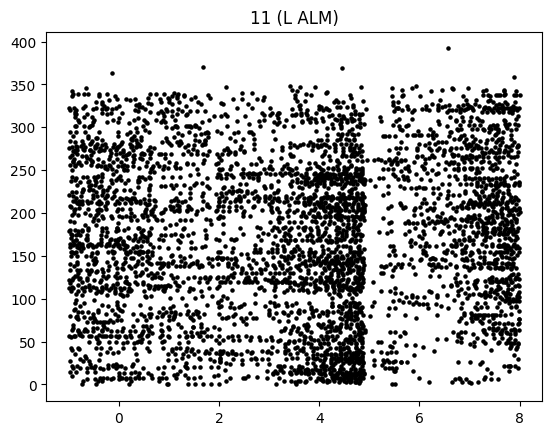

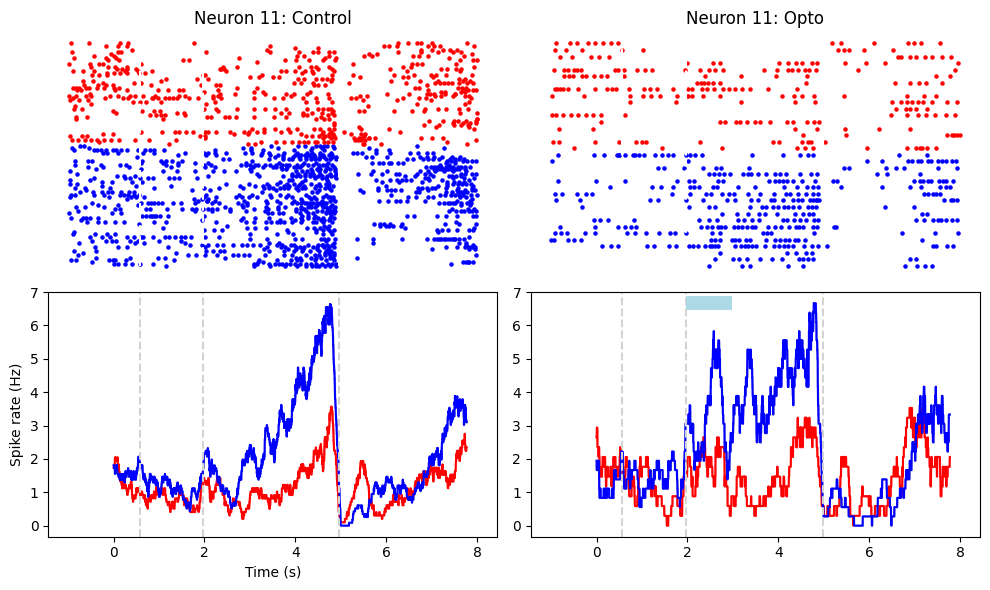

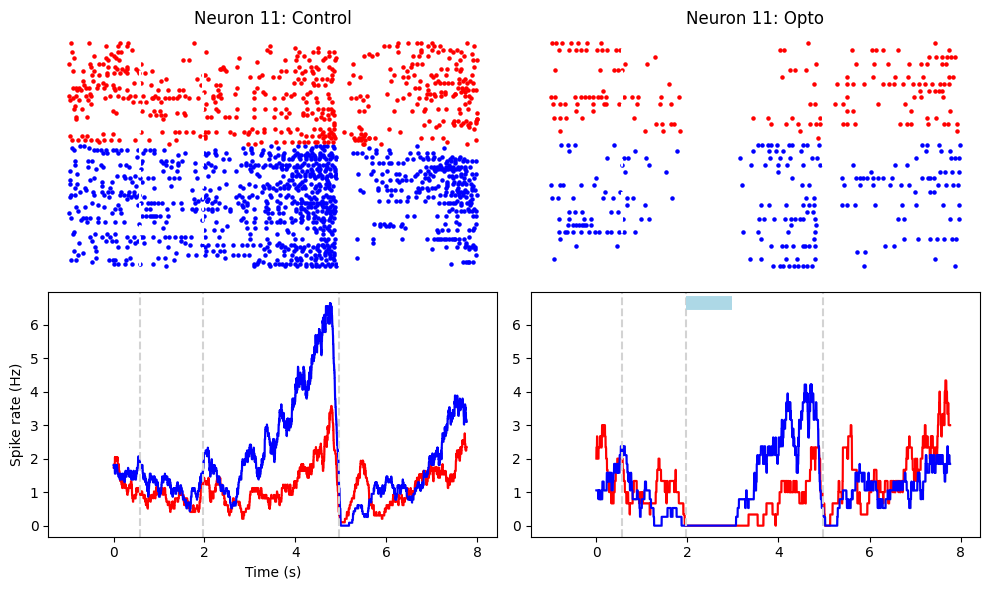

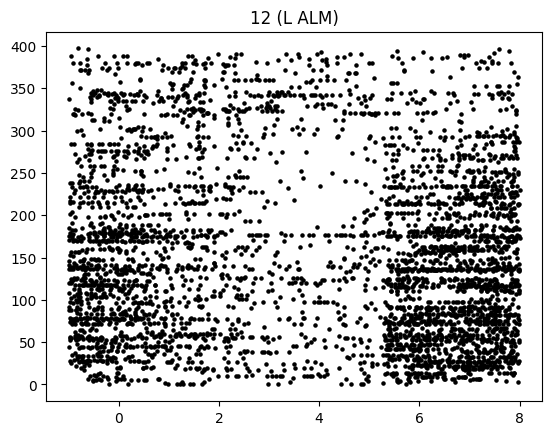

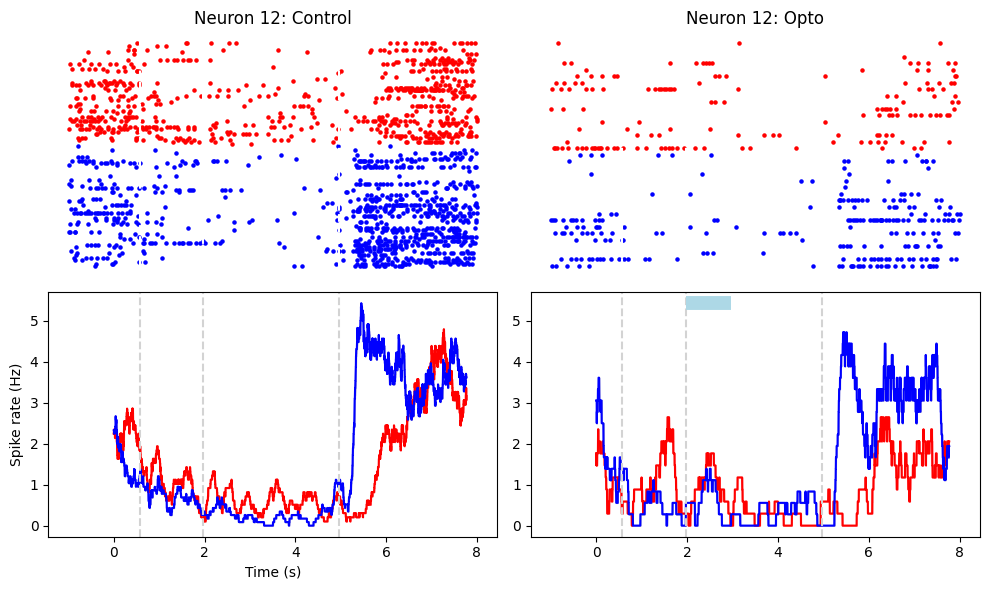

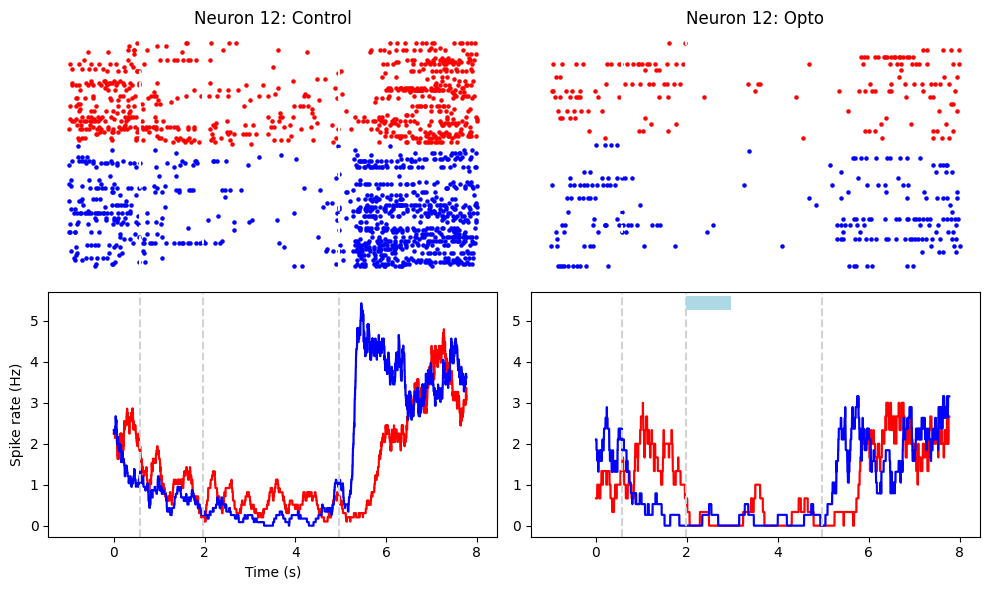

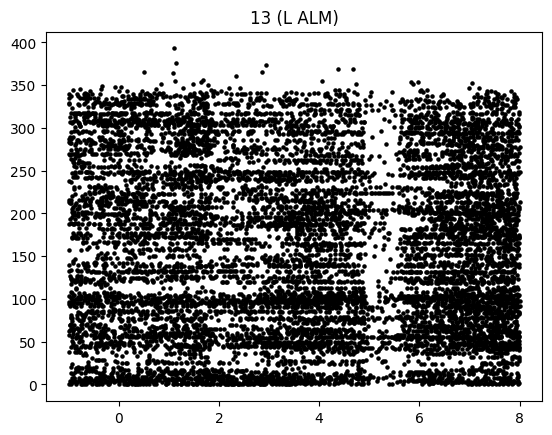

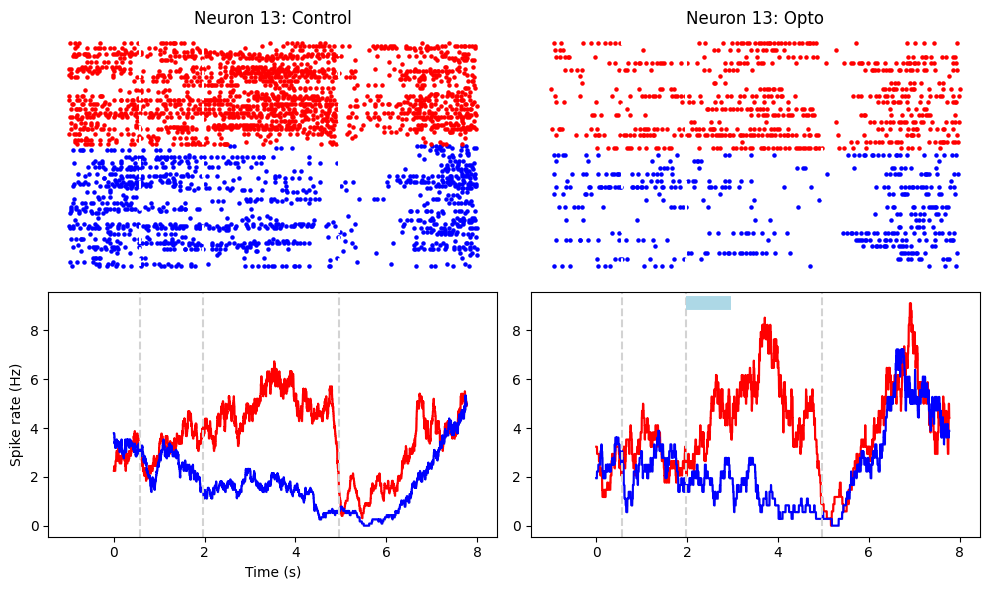

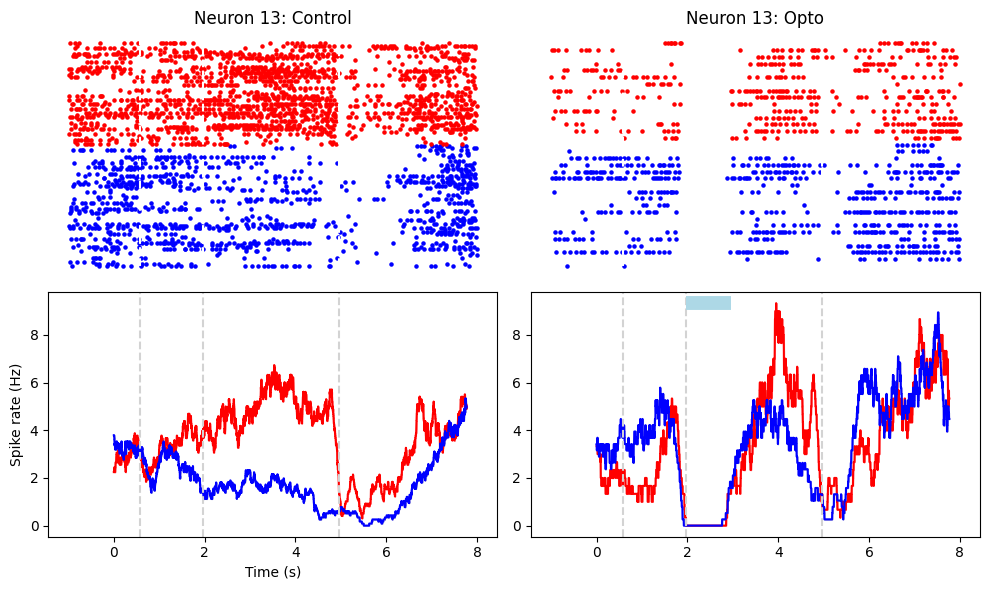

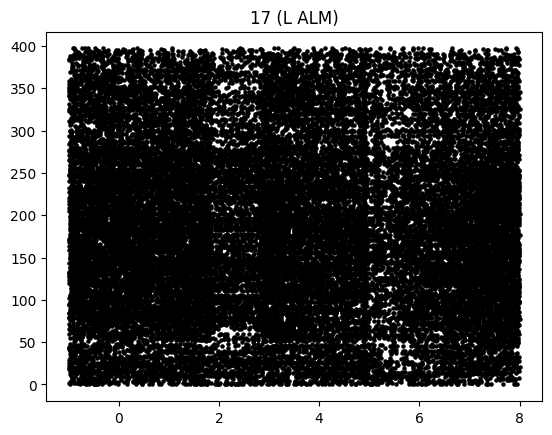

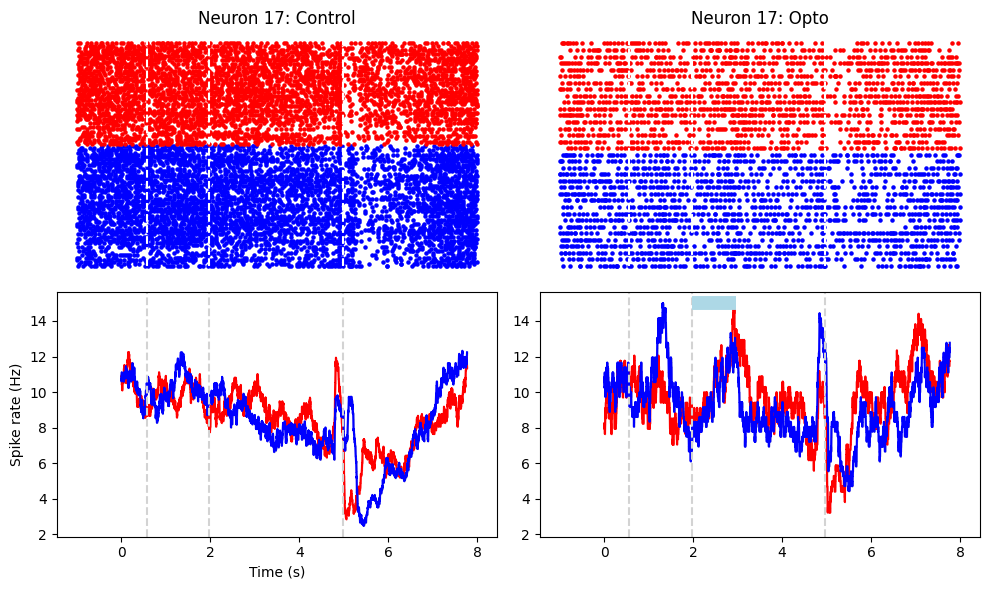

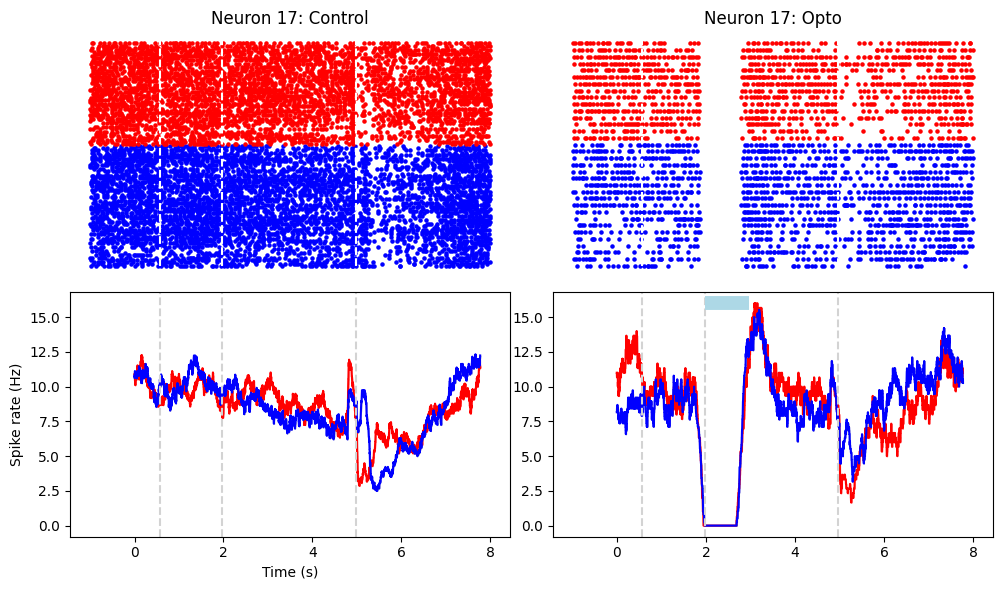

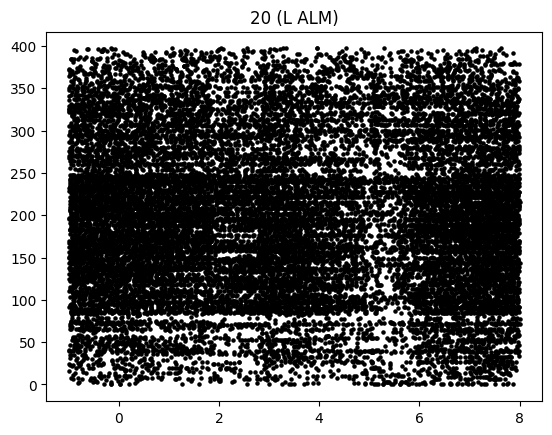

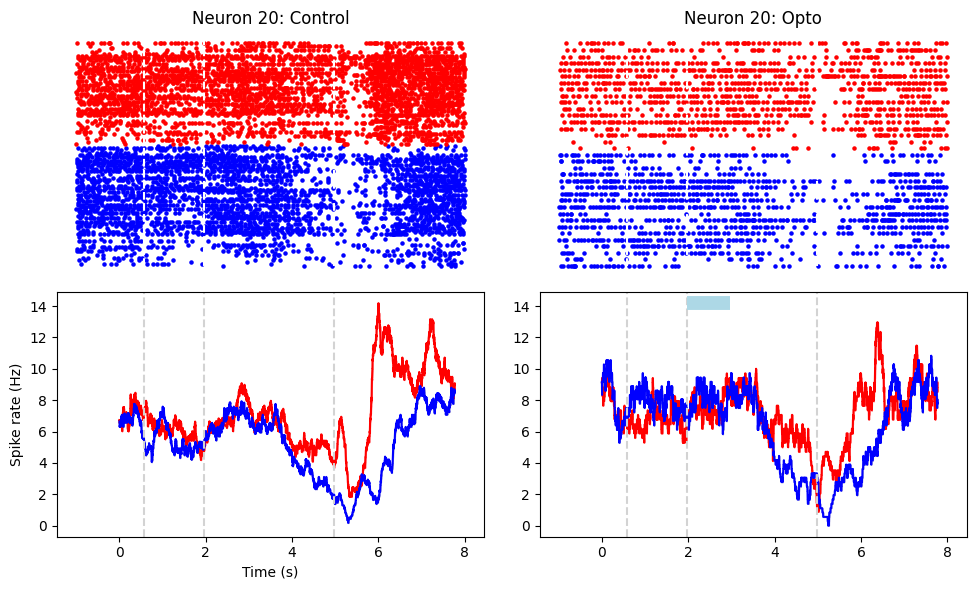

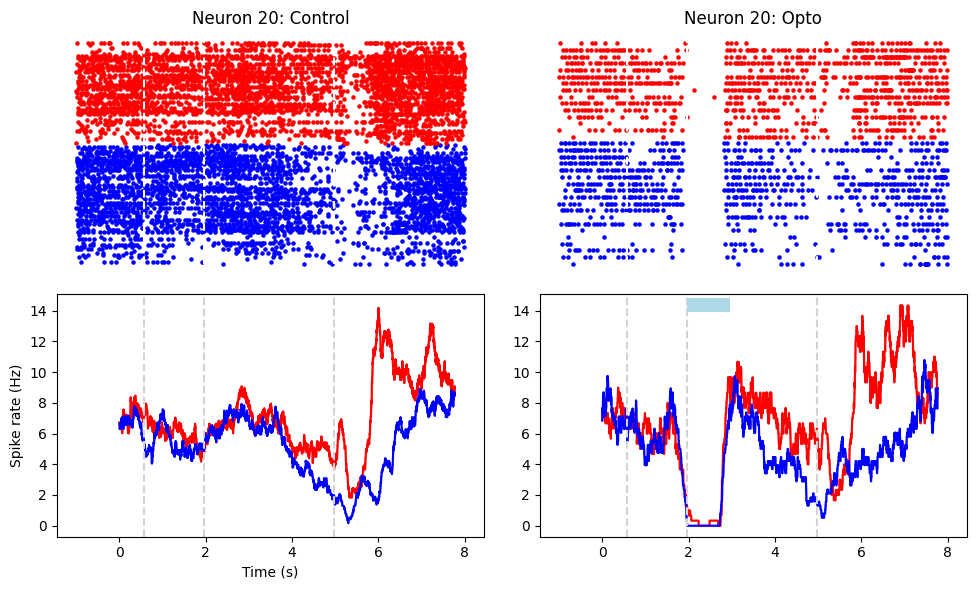

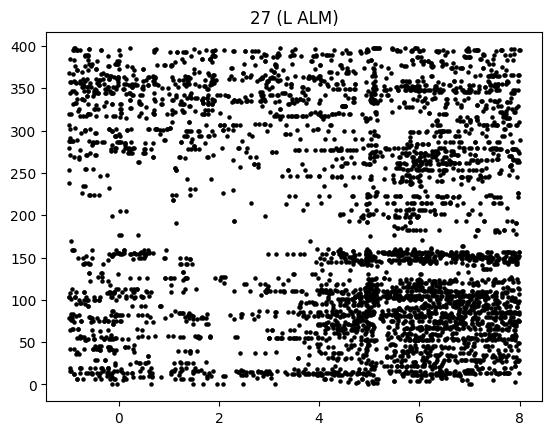

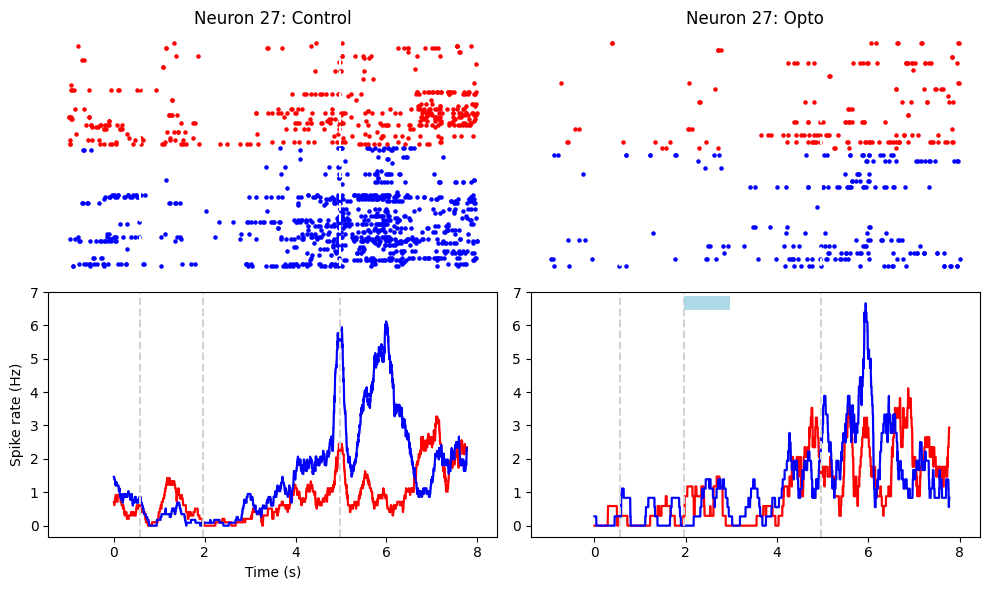

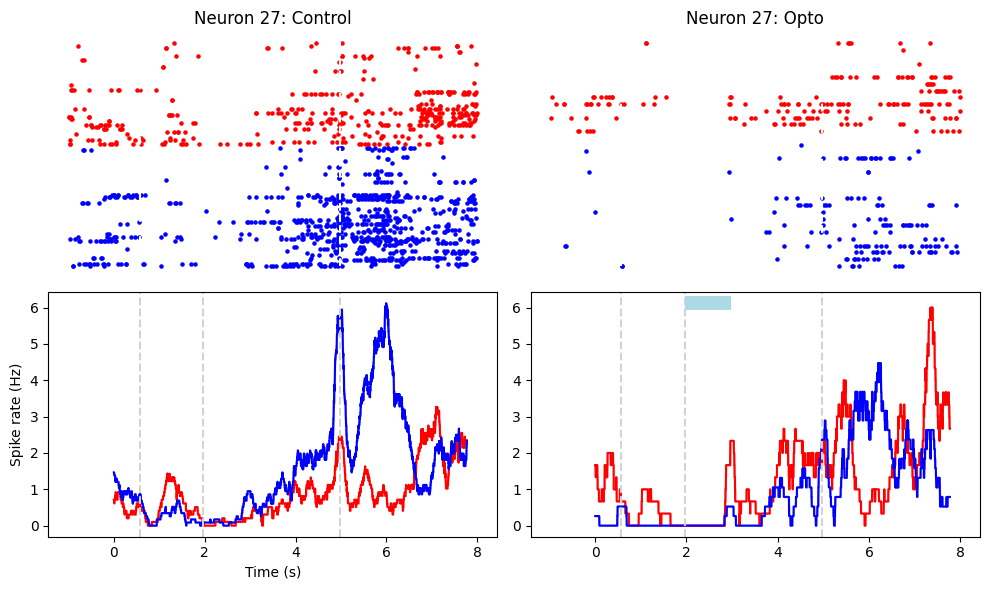

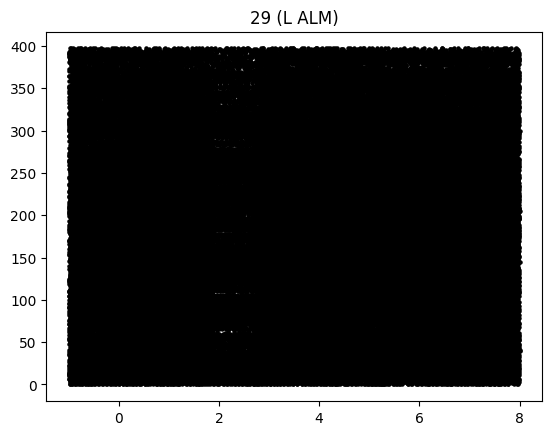

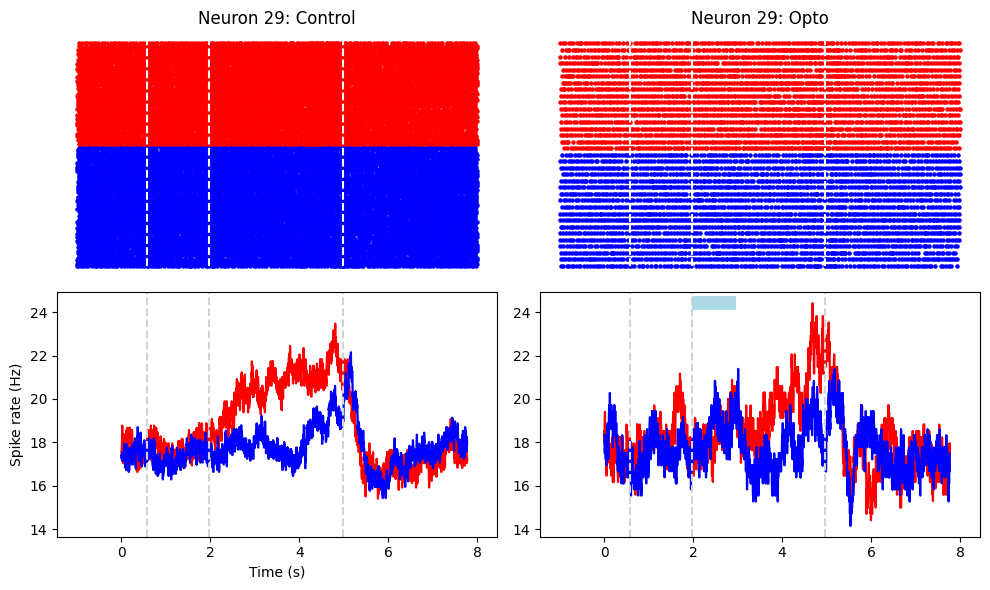

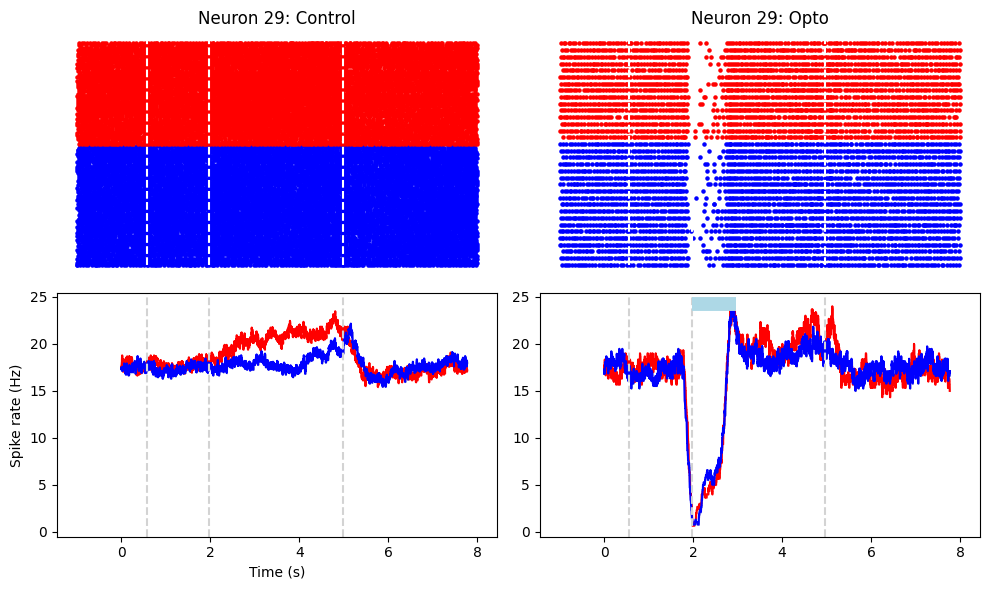

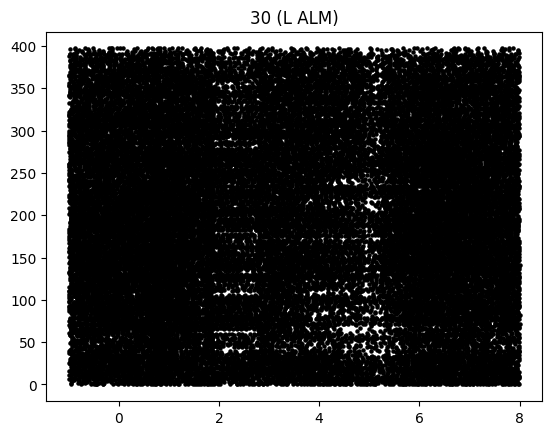

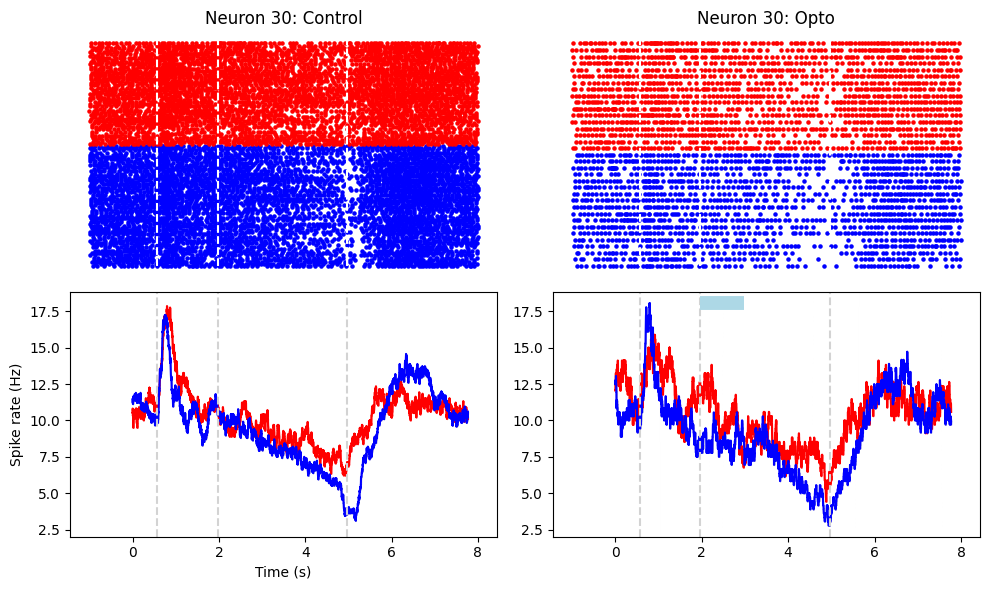

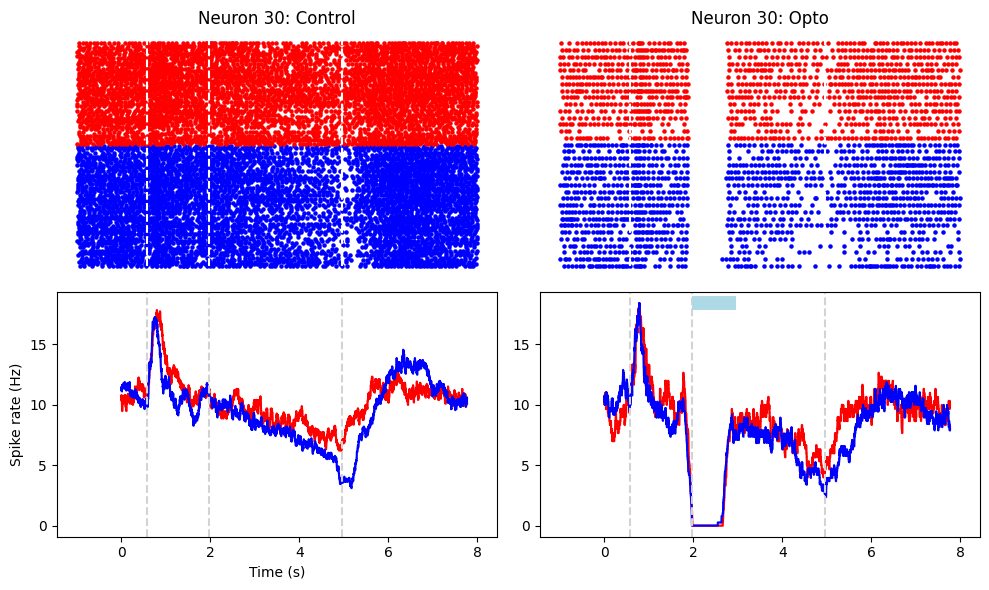

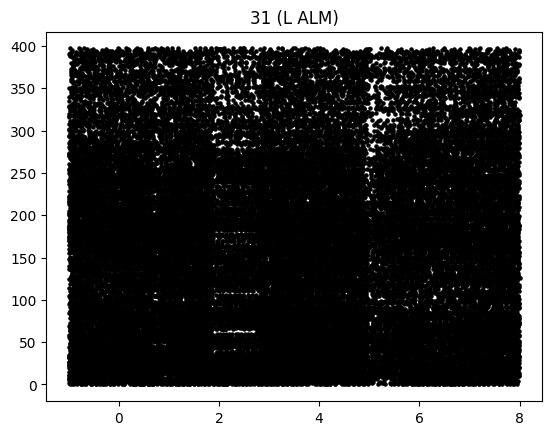

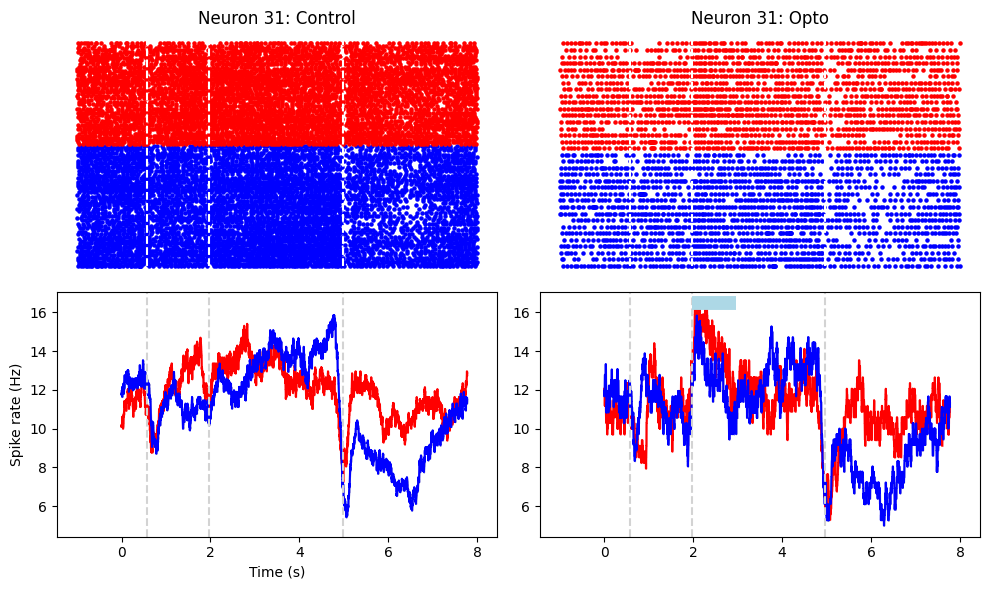

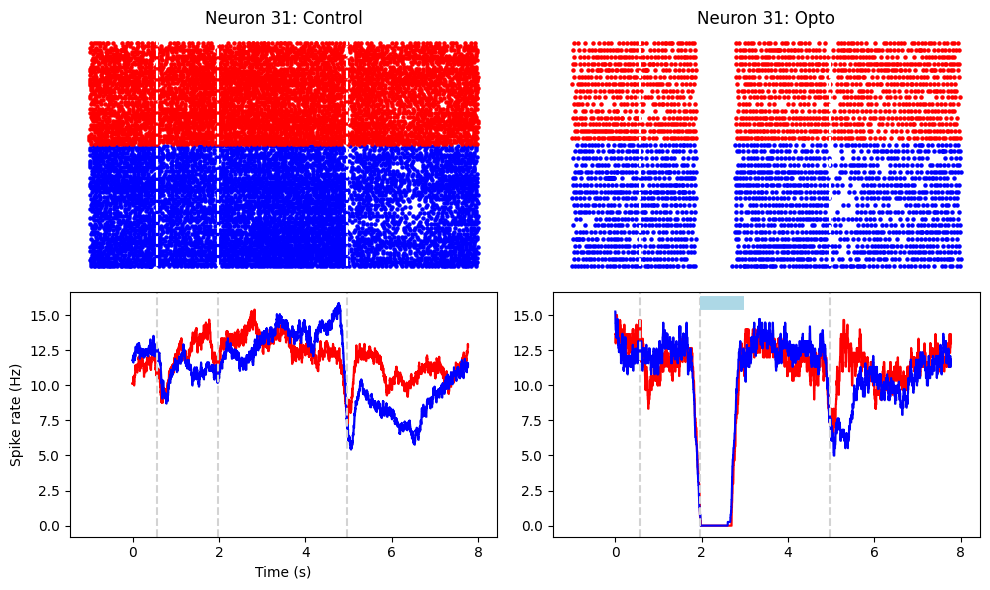

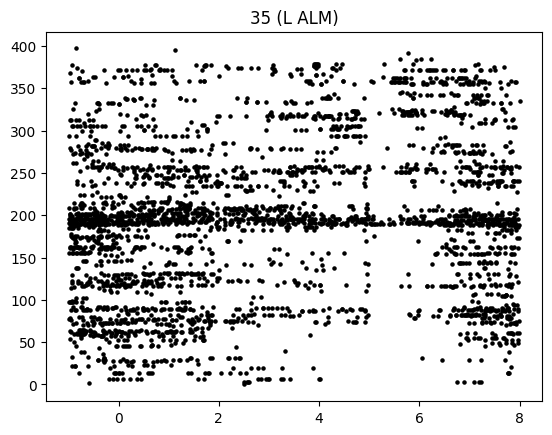

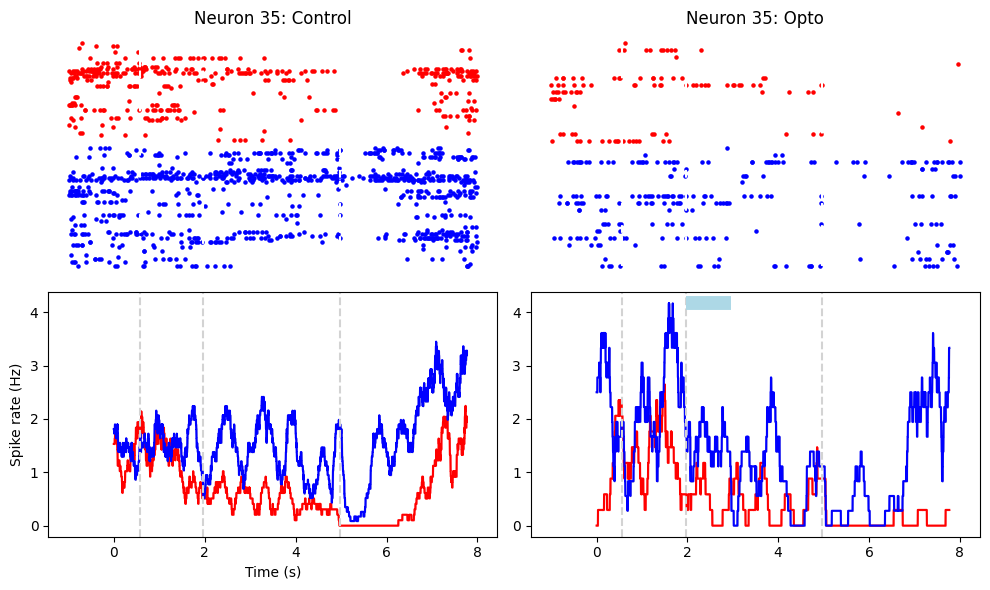

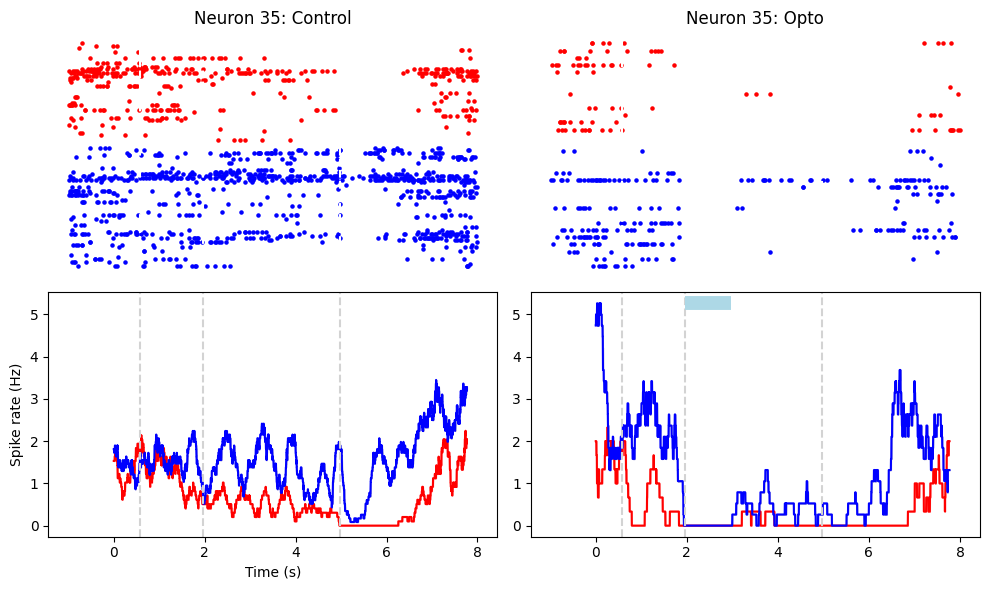

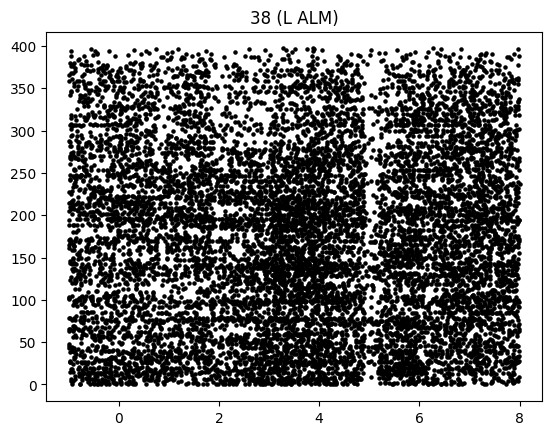

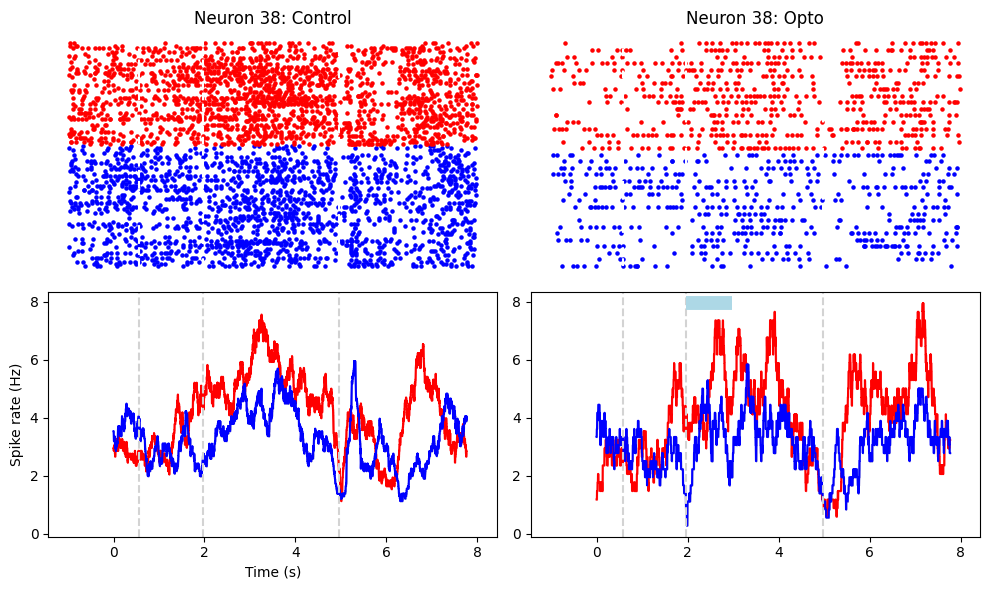

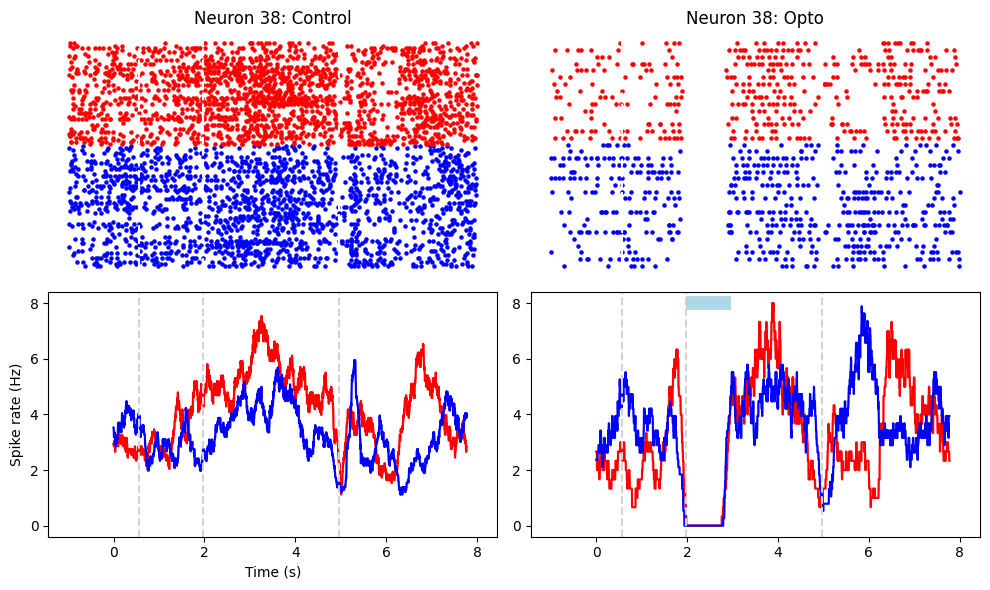

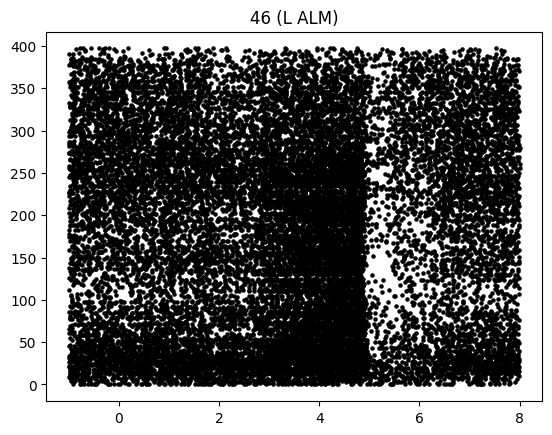

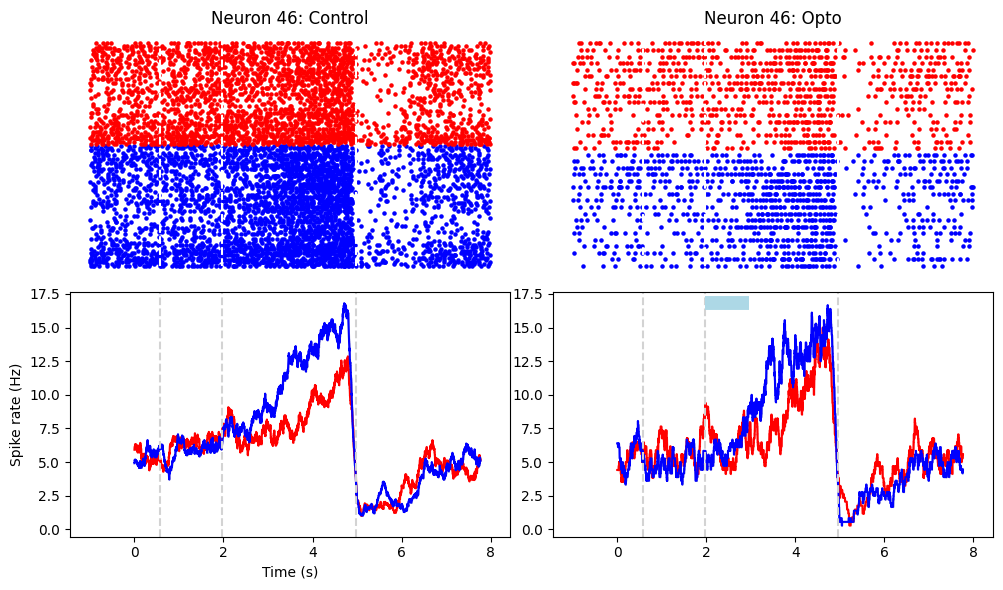

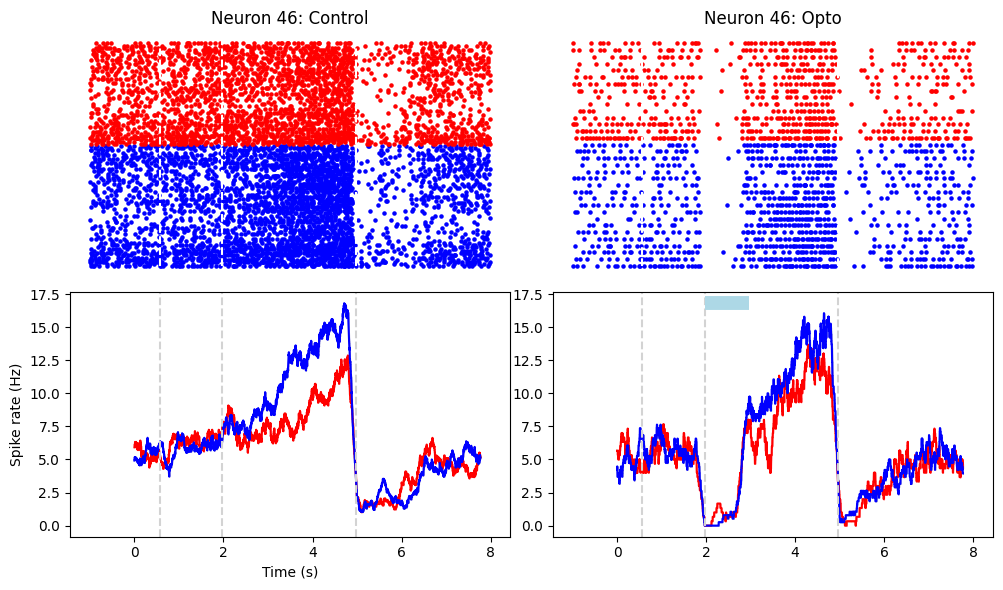

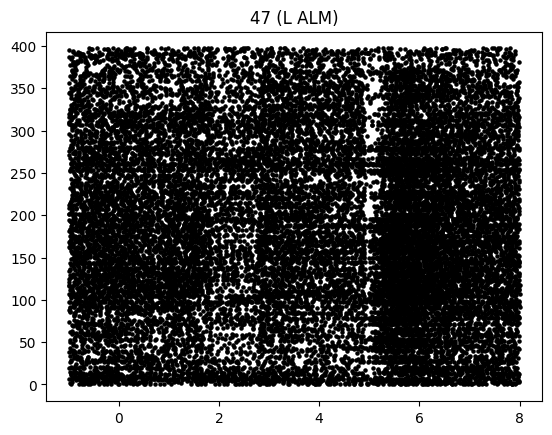

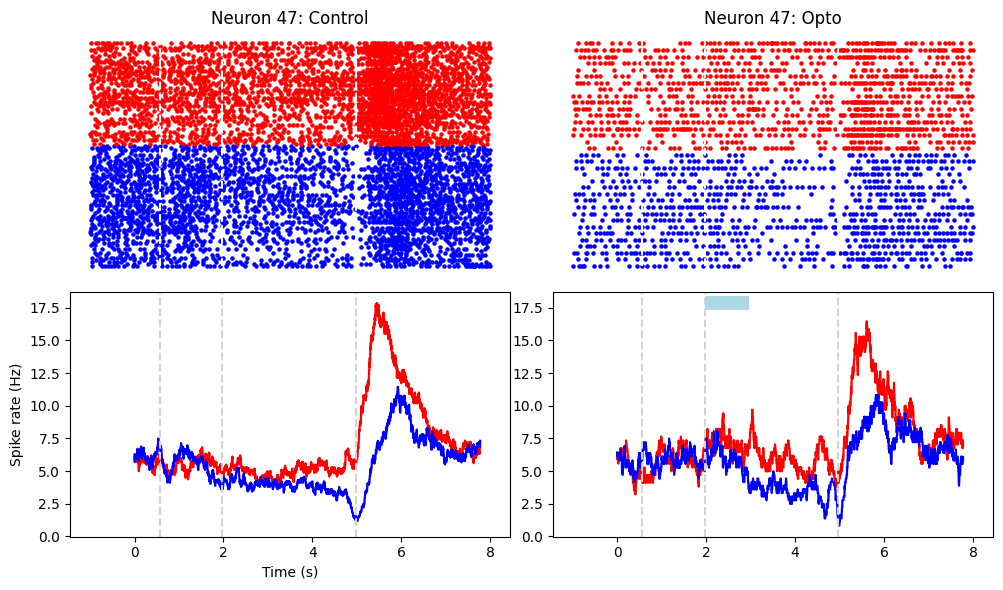

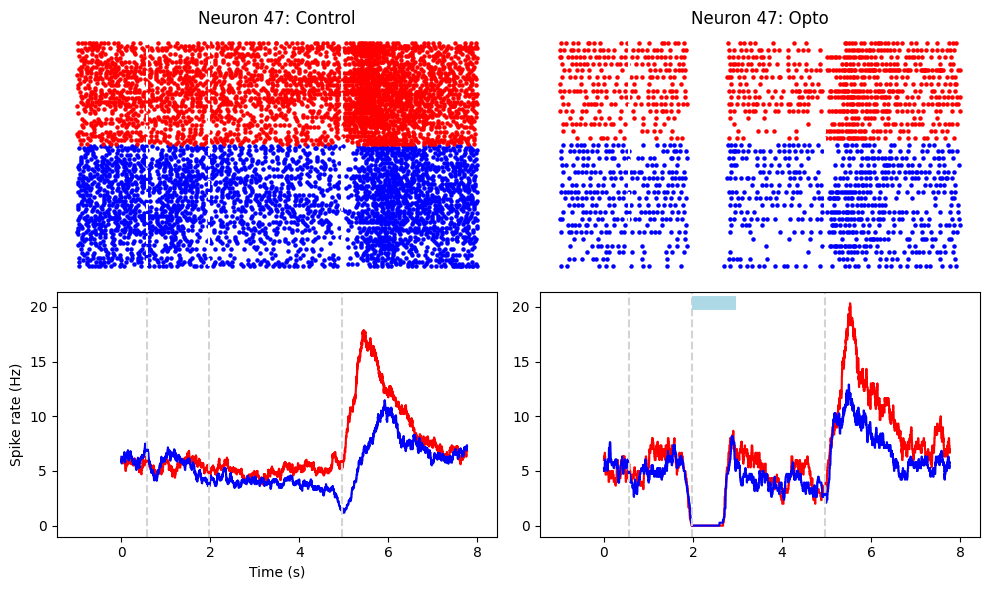

In [181]:
L_selective_neurons = s1.get_epoch_selective(epoch = (s1.delay, s1.response), p=0.05,lickdir=True)
print(len(L_selective_neurons))
for n in L_selective_neurons:
    if n in s1.L_alm_idx:
        s1.plot_raster(n)
        plt.title(f'{n} (L ALM)')
        plt.show()

        s1.plot_raster_and_PSTH(n, opto=True, stimside='R')
        s1.plot_raster_and_PSTH(n, opto=True, stimside='L')
